# MRI-Based IDH Mutation Classification — CLEAN RESTART (Option B)

**One notebook. No previous `manifest_160.csv` or saved models needed.** The notebook downloads verified UCSF-PDGM MRI files from the compact Hugging Face mirror; prepares its **own** manifests, saves patient-disjoint splits, trains transfer-learning models, tunes on validation patients and displays professor-facing metrics and figures.

**Prediction:** molecular IDH-mutant = **1**; IDH-wildtype = **0** in patients with confirmed glioma. This is **not tumour detection** and **not a medical diagnosis**.

**Research integrity:** An internal held-out test set will be created now, independent of training and validation *within this restart*. Because the original 160/350 patient ID records have been lost, some of the new test patients **may have been viewed in older experiments**. Do **not** call it a fully new independent cohort or clinical/external validation. The final test remains locked until validation model selection is complete.

**Source:** [UCSF-PDGM (TCIA)](https://www.cancerimagingarchive.net/collection/ucsf-pdgm/) and the [MedOtter compact MRI mirror](https://huggingface.co/datasets/MedOtter/UCSF-PDGM). The full TCIA data need not be downloaded. Source MRI volumes and molecular IDH labels remain linked to patient identifiers.


## 1. GPU and dependencies
In Colab choose **Runtime → Change runtime type → T4 GPU**, then execute the setup cells. Re-running an installation is usually unnecessary during the same session.

In [ ]:
%pip -q install "nibabel>=5.2,<6" "huggingface_hub>=0.26,<2" "scikit-learn>=1.4,<2" "pandas>=2,<3" "matplotlib>=3.8,<4" "scipy>=1.11,<2" "tqdm>=4.66,<5"

In [ ]:
from google.colab import drive
from pathlib import Path
from dataclasses import replace
from IPython.display import display, Markdown
import json, gc
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch

drive.mount('/content/drive')
assert torch.cuda.is_available(), 'GPU not detected. In Colab select Runtime → Change runtime type → T4 GPU.'
print('GPU:',torch.cuda.get_device_name(0),'| torch:',torch.__version__)
print('CUDA free memory (GiB):',round(torch.cuda.mem_get_info()[0]/2**30,2))


Mounted at /content/drive
GPU: Tesla T4 | torch: 2.11.0+cu130
CUDA free memory (GiB): 14.46


## 2. Recreate all Python source files inside Colab
No external `.py` files are needed. These `%%writefile` cells create the project modules in the current Colab runtime.

In [ ]:
%%writefile prepare_ucsf_manifest.py
"""Construct a strict UCSF-PDGM manifest from official clinical CSV and unpacked NIfTI files.
Usage: python prepare_ucsf_manifest.py --metadata /path/UCSF-PDGM-metadata_v5.csv --images /path/ucsf --output /path/manifest.csv
All labels are parsed exclusively from the genomics/molecular IDH column, NEVER tumour-type categories.
Unknown IDH variants are written to a REVIEW report and excluded.
"""
import re, argparse
from pathlib import Path
import pandas as pd

def parse_molecular_idh(value):
    s=str(value).strip().lower()
    if s in ('wildtype','wild-type','wt','idh-wildtype','idh-wild-type'):return 'idh-wildtype'
    # UCSF IDH biomarker stores pathogenic IDH1/IDH2 variants as e.g. IDH1 p.R132H.
    if re.fullmatch(r'idh[12]\s+p\.[a-z][0-9]+[a-z](?:\s*[,;/].*)?',s,re.I):return 'idh-mutant'
    if s in ('idh-mutant','mutant','mutated','mutated (nos)'):return 'idh-mutant'
    return None

def normalise_id(v):
    s=str(v).strip()
    if re.search(r'_FU\d+d',s,re.I): return None # repeat timepoint => do not leak
    match=re.fullmatch(r'UCSF-PDGM-(\d+)',s,re.I)
    return 'UCSF-PDGM-'+match.group(1).zfill(4) if match else None

def create_manifest(metadata,images,output):
    meta=pd.read_csv(metadata,dtype=str).fillna('');images=Path(images); rows=[]; rejected=[]
    idcol=next((x for x in meta if x.strip().lower() in ('id','patient_id','patient id')),None)
    col=next((x for x in meta if x.strip().lower()=='idh'),None)
    if not idcol or not col:raise ValueError(f'Official metadata needs ID and IDH fields; got {meta.columns.tolist()}')
    seen=set()
    for _,r in meta.iterrows():
        rid=str(r[idcol]).strip();pid=normalise_id(rid);label=parse_molecular_idh(r[col])
        if pid is None or pid in seen:
            rejected.append({'id':rid,'idh':str(r[col]),'reason':'follow-up, repeated, or invalid ID'});continue
        seen.add(pid)
        if label is None:
            rejected.append({'id':rid,'idh':str(r[col]),'reason':'unrecognised molecular label'});continue
        folders=[images/(pid+'_nifti'),images/pid]
        base=next((p for p in folders if p.is_dir()),None)
        if base is None:
            matches=list(images.rglob(pid+'_T1.nii.gz'))
            base=matches[0].parent if len(matches)==1 else None
        if base is None:
            rejected.append({'id':rid,'idh':str(r[col]),'reason':'missing patient NIfTI folder'});continue
        paths={m:base/f'{pid}_{suffix}.nii.gz' for m,suffix in [('t1','T1'),('t1ce','T1c'),('t2','T2'),('flair','FLAIR')]}
        if not all(p.is_file() for p in paths.values()):
            rejected.append({'id':rid,'idh':str(r[col]),'reason':'one or more MRI sequences missing'});continue
        seg=base/f'{pid}_tumor_segmentation.nii.gz'
        rows.append({'patient_id':pid,'idh_label':label,'cohort':'UCSF-PDGM',
                     'site':'UCSF','vendor':'GE','field_strength':'3T',
                     **{m+'_path':str(p.resolve()) for m,p in paths.items()},
                     'seg_path':str(seg.resolve()) if seg.is_file() else ''})
    p=Path(output);p.parent.mkdir(parents=True,exist_ok=True)
    frame=pd.DataFrame(rows)
    frame.to_csv(p,index=False)
    pd.DataFrame(rejected,columns=['id','idh','reason']).to_csv(p.with_name(p.stem+'_review.csv'),index=False)
    print('Usable independently labelled patients:',len(frame),'Rejected/missing:',len(rejected))
    print('Wrote',p,'and',p.with_name(p.stem+'_review.csv'))
    if frame.empty:raise ValueError('No usable images. Confirm the downloaded version, folder structure, metadata and IDH values.')
    return frame

if __name__=='__main__':
    parser=argparse.ArgumentParser();parser.add_argument('--metadata',required=True);parser.add_argument('--images',required=True);parser.add_argument('--output',required=True)
    a=parser.parse_args();create_manifest(a.metadata,a.images,a.output)


Writing prepare_ucsf_manifest.py


In [ ]:
%%writefile idh_core.py
"""Patient-level IDH classification core for research, not for clinical use.
Input: a VERIFIED patient manifest. Class 1 = IDH-mutant, 0 = IDH-wildtype.
"""
from __future__ import annotations
import os, json, random, hashlib, warnings, math
from pathlib import Path
from dataclasses import dataclass, asdict, replace
from typing import Optional
import numpy as np
import pandas as pd
from scipy import ndimage
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, confusion_matrix, brier_score_loss,
    roc_curve, precision_recall_curve)

SEQUENCES = ('t1','t1ce','t2','flair')
PATH_FIELDS = tuple(f'{m}_path' for m in SEQUENCES)
LABEL_MAP = {'idh-mutant':1, 'mutant':1, 'mutated':1, 'idh-mutated':1, '1':1,
             'idh-wildtype':0, 'idh-wild-type':0, 'wildtype':0, 'wild-type':0, '0':0}

@dataclass
class Config:
    data_dir: str = '/content/drive/MyDrive/IDH_Audit/dataset'
    manifest_csv: str = '/content/drive/MyDrive/IDH_Audit/manifest.csv'
    output_dir: str = '/content/drive/MyDrive/IDH_Audit/results'
    cache_dir: str = '/content/idh_preprocessed' # Colab local disk is much faster
    experiment_mode: str = 'baseline'       # baseline, a1, a2, a3, a4, combined, all
    domain_field: str = 'vendor'           # use site if vendor not available
    sequences: tuple = SEQUENCES
    voxel_spacing: float = 1.5
    volume_shape: tuple = (96,96,96)
    input_resolution: int = 96
    adjacent_slices: int = 3
    locations: int = 3
    batch_size: int = 2
    epochs: int = 20
    lr: float = 3e-4
    weight_decay: float = 1e-4
    seed: int = 123
    test_fraction: float = 0.20
    val_fraction: float = 0.20 # fraction of ALL patients
    mixed_precision: bool = True
    accumulation_steps: int = 2
    workers: int = 2
    early_patience: int = 5
    dropout: float = 0.2
    hidden_dim: int = 128
    backbone: str = 'light_cnn'     # light_cnn or resnet18
    pretrained_backbone: bool = False # ImageNet weights ONLY when opted in
    freeze_pretrained_epochs: int = 0 # freeze ResNet ImageNet backbone before fine-tuning
    use_class_weight: bool = True
    use_n4_bias_correction: bool = False  # For raw MRI only; often redundant for UCSF-PDGM
    assume_coregistered: bool = True      # DO NOT use this with unaligned raw scans
    augment_strength: float = 0.4
    consistency_lambda: float = 0.5
    consistency_warmup_epochs: int = 3
    adversarial_lambda: float = 0.1
    threshold: float = 0.5
    run_explanations: bool = False
    run_lodo: bool = False
    external_manifest_csv: str = ''
    resume: bool = False
    device: str = 'cuda' if torch.cuda.is_available() else 'cpu'

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def write_json(obj, path):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    def encode(x):
        if isinstance(x, (np.integer, np.floating)): return x.item()
        if isinstance(x,np.ndarray): return x.tolist()
        if isinstance(x,Path): return str(x)
        if isinstance(x,float) and not np.isfinite(x): return None
        raise TypeError(f'Not JSON serialisable: {type(x)}')
    with open(path,'w') as f: json.dump(obj,f,indent=2,default=encode,allow_nan=False)

def load_manifest(csv_path, data_dir='', require_labels=True, sequences=SEQUENCES):
    p=Path(csv_path)
    if not p.is_file(): raise FileNotFoundError(f'Missing patient manifest: {p}. See DATASET_GUIDE.md')
    df=pd.read_csv(p, dtype={'patient_id':str}).fillna('')
    required=['patient_id']+(["idh_label"] if require_labels else [])+[f'{s}_path' for s in sequences]
    missing=set(required)-set(df.columns)
    if missing: raise ValueError(f'Manifest is missing required columns: {sorted(missing)}')
    if df.empty: raise ValueError('Manifest is empty')
    df['patient_id']=df.patient_id.astype(str).str.strip()
    if (df.patient_id=='').any(): raise ValueError('Empty patient_id found')
    if df.patient_id.duplicated().any():
        raise ValueError('Duplicate patient_id rows, including follow-up visits. Resolve to one independent patient first: '+
                         ', '.join(df.loc[df.patient_id.duplicated(),'patient_id'].head().tolist()))
    if require_labels:
        labels=df.idh_label.astype(str).str.strip().str.lower()
        bad=sorted(set(labels)-set(LABEL_MAP))
        if bad: raise ValueError('Unsupported/uncertain IDH labels; only use molecular ground truth: '+str(bad[:10]))
        df['idh_label']=labels.map(LABEL_MAP).astype(int)
    elif 'idh_label' in df:
        df=df.drop(columns='idh_label')
    root=Path(data_dir or p.parent).expanduser().resolve()
    for mod in sequences:
        col=f'{mod}_path'; arr=[]
        for raw in df[col]:
            name=str(raw).strip()
            if not name: raise ValueError(f'Missing required {col}; patient: {df.iloc[len(arr)].patient_id}')
            candidate=Path(name).expanduser()
            candidate=(candidate if candidate.is_absolute() else root/candidate).resolve()
            if not candidate.is_file(): raise FileNotFoundError(f'{df.iloc[len(arr)].patient_id}: {candidate}')
            if not (str(candidate).lower().endswith(('.nii','.nii.gz'))):
                raise ValueError(f'Expected NIfTI (.nii/.nii.gz): {candidate}')
            arr.append(str(candidate))
        df[col]=arr
    if 'seg_path' in df:
        resolved=[]
        for raw in df.seg_path:
            if not str(raw).strip(): resolved.append(''); continue
            f=Path(str(raw)); f=f if f.is_absolute() else root/f
            if not f.is_file(): raise FileNotFoundError(f'Optional segmentation path invalid: {f}')
            resolved.append(str(f.resolve()))
        df['seg_path']=resolved
    # Reject accidental self-reuse of a single series as two distinct MRI sequences.
    for _,row in df.iterrows():
        seq_paths=[str(row[f'{name}_path']) for name in sequences]
        if len(set(seq_paths))!=len(seq_paths):
            raise ValueError(f'{row.patient_id}: same MRI file assigned to multiple sequence fields')
    # If identical image file is assigned to multiple patient IDs, stop.
    for c in (f'{s}_path' for s in sequences):
        if df[c].duplicated().any(): raise ValueError(f'Cross-patient reuse of {c}; inspect duplicates')
    return df.reset_index(drop=True)

def check_file_hashes(df, columns=PATH_FIELDS):
    """Optional expensive audit for exact identical files (not perceptual near duplicates)."""
    records=[]; seen={}
    for r in df.itertuples(index=False):
        for col in columns:
            if col not in df: continue
            p=Path(getattr(r,col)); h=hashlib.sha256()
            with p.open('rb') as stream:
                while True:
                    block=stream.read(2**20)
                    if not block: break
                    h.update(block)
            digest=h.hexdigest()
            if digest in seen and seen[digest][0]!=r.patient_id:
                records.append({'patient_a':seen[digest][0],'patient_b':r.patient_id,'path_a':seen[digest][1],'path_b':str(p)})
            seen[digest]=(r.patient_id,str(p))
    return pd.DataFrame(records)

def patient_split(df, config):
    if 'idh_label' not in df: raise ValueError('Cannot split for training without molecular labels')
    if df.idh_label.nunique()!=2: raise ValueError('Dataset must include both IDH classes')
    if config.val_fraction+config.test_fraction>=0.8: raise ValueError('Development fraction too small')
    counts=df.idh_label.value_counts()
    if counts.min()<3: raise ValueError('Too few patients in at least one class for 3 independent splits')
    try:
        dev,test=train_test_split(df,test_size=config.test_fraction,stratify=df.idh_label,random_state=config.seed)
        relative_val=config.val_fraction/(1-config.test_fraction)
        train,val=train_test_split(dev,test_size=relative_val,stratify=dev.idh_label,random_state=config.seed+1)
    except ValueError as ex:
        raise ValueError('Class sizes insufficient for stratified train/val/test splitting: '+str(ex)) from ex
    parts={'train':train.reset_index(drop=True),'val':val.reset_index(drop=True),'test':test.reset_index(drop=True)}
    assert sum(len(d) for d in parts.values())==len(df)
    assert all(parts[a].patient_id.isin(parts[b].patient_id).sum()==0 for a in parts for b in parts if a!=b)
    return parts

def save_splits(splits,path):
    p=Path(path); p.mkdir(parents=True,exist_ok=True)
    for k,d in splits.items(): d.to_csv(p/f'{k}_manifest.csv',index=False)

def _load_nifti(path):
    import nibabel as nib
    image=nib.as_closest_canonical(nib.load(str(path)))
    if len(image.shape)!=3: raise ValueError(f'Expected 3D MRI: {path} shape={image.shape}')
    return image

def _n4_correct(img):
    import SimpleITK as sitk
    import nibabel as nib
    x=np.asarray(img.get_fdata(dtype=np.float32), dtype=np.float32)
    m=(x>0).astype(np.uint8)
    if m.sum()==0: raise ValueError('Empty brain mask for N4 correction')
    itk=sitk.GetImageFromArray(x); mask=sitk.GetImageFromArray(m)
    corrected=sitk.N4BiasFieldCorrectionImageFilter().Execute(itk,mask)
    return nib.Nifti1Image(sitk.GetArrayFromImage(corrected),img.affine)

def _centre_crop_pad(vol,centre,shape):
    result=np.zeros(tuple(shape),dtype=np.float32)
    in_slices=[]; out_slices=[]
    for d,(sz,c,s) in enumerate(zip(vol.shape,centre,shape)):
        st=int(round(c))-s//2; end=st+s; lo=max(0,st); hi=min(sz,end)
        if hi<=lo: continue
        in_slices.append(slice(lo,hi)); out_slices.append(slice(lo-st,hi-st))
    result[tuple(out_slices)]=vol[tuple(in_slices)]
    return result

def preprocess_patient(row, config):
    """Orientation standardise, affine-resample into a common physical grid, mask, crop, normalise.
    Assumes source modalities have been registered or are in aligned physical coordinates.
    Simply resampling DOES NOT perform deformable/rigid registration of unaligned scans.
    """
    import nibabel as nib
    from nibabel.processing import resample_to_output, resample_from_to
    if not config.assume_coregistered:
        raise ValueError('Unregistered MRI input: register T1/T1ce/T2/FLAIR externally first (e.g., ANTs), QC, then set assume_coregistered=True.')
    reference_name='t1ce' if 't1ce' in config.sequences else config.sequences[0]
    original={name:_load_nifti(row[f'{name}_path']) for name in config.sequences}
    if config.use_n4_bias_correction:
        original={k:_n4_correct(v) for k,v in original.items()}
    ref=resample_to_output(original[reference_name],voxel_sizes=(config.voxel_spacing,)*3,order=1)
    tgt=(ref.shape,ref.affine)
    aligned={name: np.asarray((ref if name==reference_name else
                       resample_from_to(vol,tgt,order=1)).get_fdata(dtype=np.float32),dtype=np.float32)
                       for name,vol in original.items()}
    if any(not np.isfinite(x).all() for x in aligned.values()): raise ValueError('NaN/Inf in image')
    masks=np.stack([np.abs(x)>1e-6 for x in aligned.values()]).any(0)
    if masks.sum()<500: raise ValueError(f'Empty/near-empty MRI for patient {row["patient_id"]}')
    coords=np.argwhere(masks); centre=np.median(coords,axis=0).astype(int)
    seg=None
    if 'seg_path' in row.index and isinstance(row['seg_path'],str) and row['seg_path'].strip():
        seg_image=_load_nifti(row['seg_path'])
        seg=resample_from_to(seg_image,tgt,order=0).get_fdata(dtype=np.float32)>0
        if seg.sum()>0: centre=np.median(np.argwhere(seg),axis=0).astype(int)
    arr=[]
    for name in config.sequences:
        vol=_centre_crop_pad(aligned[name],centre,config.volume_shape)
        mask=(np.abs(vol)>1e-6)
        if mask.sum()<100: raise ValueError(f'Empty aligned {name}, check registration and affine: {row["patient_id"]}')
        vals=vol[mask]; low,high=np.percentile(vals,[0.5,99.5]); vol=np.clip(vol,low,high)
        vals=vol[mask]; vol[mask]=(vals-vals.mean())/(vals.std()+1e-6)
        vol[~mask]=0
        arr.append(np.clip(vol,-5,5).astype(np.float32))
    seg_out=_centre_crop_pad(seg.astype(np.float32),centre,config.volume_shape)>0 if seg is not None else None
    # Anatomical alignment QC: image masks must overlap; low overlap often means an affine/registration error.
    overlap_masks=[np.abs(a)>1e-6 for a in arr]
    ref_mask=overlap_masks[0]
    overlap=[float((ref_mask & m).sum() / (ref_mask | m).sum()) for m in overlap_masks[1:]]
    if overlap and min(overlap)<0.20:
        raise ValueError(f'Sequence alignment failed QC (foreground IoU={overlap}), patient={row["patient_id"]}')
    return np.stack(arr).astype(np.float32),seg_out

def _cache_key(row,cfg):
    identity={'id':str(row.patient_id),'vol_shape':cfg.volume_shape,'spacing':cfg.voxel_spacing,
              'sequences':cfg.sequences,'n4':cfg.use_n4_bias_correction,'version':'optionB_v4'}
    for k in [*PATH_FIELDS,'seg_path']:
        if k in row.index and str(row[k]):
            p=Path(str(row[k])); identity[k]=[str(p),p.stat().st_size,p.stat().st_mtime_ns]
    return hashlib.sha256(json.dumps(identity,sort_keys=True,default=str).encode()).hexdigest()[:20]

def cached_preprocess(row,cfg):
    root=Path(cfg.cache_dir); root.mkdir(parents=True,exist_ok=True)
    dest=root/(_cache_key(row,cfg)+'.npz')
    if not dest.exists():
        x,seg=preprocess_patient(row,cfg)
        tmp=dest.with_suffix('.temp.npz')
        np.savez_compressed(tmp, x=x.astype(np.float16),seg=(seg.astype(np.uint8) if seg is not None else np.zeros((0,),dtype=np.uint8)))
        os.replace(tmp,dest)
    with np.load(dest) as item:
        x=item['x'].astype(np.float32); seg=item['seg'].astype(bool)
        return x,seg if seg.size else None

def volume_to_25d(vol, cfg, seg=None):
    """[M,X,Y,Z] -> [3*locations,M*adjacent,H,W]; centre chosen by tumour mask if available.
    Strict channel order: for each plane, modalities, then adjacent slices.
    """
    x=torch.as_tensor(vol,dtype=torch.float32)
    if x.ndim!=4 or x.shape[0]!=len(cfg.sequences): raise ValueError('Expected [modalities,X,Y,Z]')
    if cfg.adjacent_slices%2!=1 or cfg.adjacent_slices<1: raise ValueError('adjacent_slices must be odd')
    selected=[]
    for axis in (0,1,2):
        if seg is not None and seg.sum()>0:
            idx=np.where(seg)[axis]; lo=int(np.quantile(idx,0.20)); hi=int(np.quantile(idx,0.80))
        else:
            lo=int(x.shape[axis+1]*.30); hi=int(x.shape[axis+1]*.70)
        centres=np.rint(np.linspace(lo,hi,cfg.locations)).astype(int)
        for centre in centres:
            slices=[]
            for m in range(len(cfg.sequences)):
                for offset in range(-(cfg.adjacent_slices//2),cfg.adjacent_slices//2+1):
                    cut=int(np.clip(centre+offset,0,x.shape[axis+1]-1))
                    plane=x[m].select(axis,cut)
                    slices.append(plane)
            view=torch.stack(slices)[:,None,:,:]
            view=torch.nn.functional.interpolate(view,size=(cfg.input_resolution,cfg.input_resolution),mode='bilinear',align_corners=False)[:,0]
            selected.append(view)
    return torch.stack(selected)

class PatientDataset(Dataset):
    def __init__(self,df,cfg,include_labels=True):
        self.df=df.reset_index(drop=True); self.cfg=cfg; self.include_labels=include_labels
    def __len__(self): return len(self.df)
    def __getitem__(self,i):
        row=self.df.iloc[i]
        # Cache only deterministic, unaugmented views. Training augmentations remain stochastic.
        views=Path(self.cfg.cache_dir)/'views'
        views.mkdir(parents=True,exist_ok=True)
        key=hashlib.sha256((str(_cache_key(row,self.cfg))+str(self.cfg.sequences)+
             f'{self.cfg.locations}_{self.cfg.adjacent_slices}_{self.cfg.input_resolution}').encode()).hexdigest()[:18]
        file=views/(str(row.patient_id)+'_'+key+'.npy')
        if not file.exists():
            v,seg=cached_preprocess(row,self.cfg)
            x=volume_to_25d(v,self.cfg,seg)
            tmp=file.with_suffix('.tmp.npy')
            np.save(tmp,x.numpy().astype(np.float16))
            os.replace(tmp,file)
        x=torch.from_numpy(np.load(file).astype(np.float32))
        label=float(row.idh_label) if self.include_labels else -1.0
        return x,torch.tensor(label,dtype=torch.float32),str(row.patient_id)

def loaders_from_splits(splits,cfg,balanced=False):
    datasets={k:PatientDataset(v,cfg) for k,v in splits.items()}
    sampler=None
    if balanced:
        df=splits['train']; col=cfg.domain_field
        if col not in df or not df[col].astype(str).str.strip().all():
            raise ValueError(f'Balanced sampling requested, but {col} unavailable')
        weights=1.0/df.groupby([col,'idh_label'])['patient_id'].transform('count').to_numpy()
        weights=weights/weights.mean()
        sampler=WeightedRandomSampler(torch.tensor(weights,dtype=torch.double),num_samples=len(df),replacement=True)
    return {k:DataLoader(ds,batch_size=cfg.batch_size,shuffle=k=='train' and sampler is None,
                     sampler=sampler if k=='train' else None,num_workers=cfg.workers,
                     pin_memory=cfg.device.startswith('cuda'),persistent_workers=cfg.workers>0)
              for k,ds in datasets.items()}

class ConvBlock(nn.Module):
    def __init__(self,c1,c2):
        super().__init__(); self.layers=nn.Sequential(nn.Conv2d(c1,c2,3,padding=1,bias=False),
            nn.BatchNorm2d(c2),nn.SiLU(),nn.Conv2d(c2,c2,3,padding=1,bias=False),
            nn.BatchNorm2d(c2),nn.SiLU(),nn.MaxPool2d(2))
    def forward(self,x): return self.layers(x)

class GradientReversal(torch.autograd.Function):
    @staticmethod
    def forward(ctx,x,weight): ctx.weight=weight; return x.view_as(x)
    @staticmethod
    def backward(ctx,grad): return -ctx.weight*grad,None

class MRI25DNet(nn.Module):
    def __init__(self,cfg,n_domains=0):
        super().__init__(); inp=len(cfg.sequences)*cfg.adjacent_slices; h=cfg.hidden_dim
        self.locations=cfg.locations; self.n_views=3*cfg.locations
        if cfg.backbone == 'light_cnn':
            self.encoder=nn.Sequential(ConvBlock(inp,24),ConvBlock(24,48),ConvBlock(48,96),
                                      nn.Conv2d(96,h,3,padding=1),nn.SiLU())
        elif cfg.backbone == 'resnet18':
            from torchvision.models import resnet18, ResNet18_Weights
            backbone=resnet18(weights=ResNet18_Weights.DEFAULT if cfg.pretrained_backbone else None)
            old=backbone.conv1
            backbone.conv1=nn.Conv2d(inp,old.out_channels,kernel_size=old.kernel_size,
                                    stride=old.stride,padding=old.padding,bias=False)
            if cfg.pretrained_backbone:
                with torch.no_grad():
                    backbone.conv1.weight.copy_(old.weight.mean(1,keepdim=True).repeat(1,inp,1,1)*(3.0/inp))
            self.encoder=nn.Sequential(*list(backbone.children())[:-2],nn.Conv2d(512,h,1),nn.SiLU())
        elif cfg.backbone == 'efficientnet_b0':
            from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
            backbone=efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT if cfg.pretrained_backbone else None)
            old=backbone.features[0][0]
            new=nn.Conv2d(inp,old.out_channels,kernel_size=old.kernel_size,
                          stride=old.stride,padding=old.padding,bias=False)
            if cfg.pretrained_backbone:
                with torch.no_grad():
                    new.weight.copy_(old.weight.mean(dim=1,keepdim=True).repeat(1,inp,1,1)*(3.0/inp))
            backbone.features[0][0]=new
            self.encoder=nn.Sequential(backbone.features,nn.Conv2d(1280,h,1),nn.SiLU())
        else: raise ValueError('backbone must be light_cnn, resnet18 or efficientnet_b0')
        self.pool=nn.AdaptiveAvgPool2d(1)
        self.view_embedding=nn.Embedding(3,h)
        self.attention=nn.Sequential(nn.Linear(h,h//2),nn.Tanh(),nn.Linear(h//2,1))
        self.classifier=nn.Sequential(nn.LayerNorm(h),nn.Dropout(cfg.dropout),nn.Linear(h,1))
        self.domain_head=nn.Sequential(nn.LayerNorm(h),nn.Linear(h,h//2),nn.ReLU(),nn.Linear(h//2,n_domains)) if n_domains>1 else None
    def forward(self,x,grl_lambda=0.0,return_embedding=False):
        if x.ndim!=5 or x.shape[1]!=self.n_views: raise ValueError(f'Expected input [B,{self.n_views},C,H,W], got {tuple(x.shape)}')
        b,n,c,h,w=x.shape
        maps=self.encoder(x.reshape(b*n,c,h,w))
        v=self.pool(maps).flatten(1).reshape(b,n,-1)
        plane_ids=torch.arange(n,device=x.device)//self.locations
        v=v+self.view_embedding(plane_ids)[None]
        weights=torch.softmax(self.attention(v),dim=1)
        z=(v*weights).sum(1)
        logits=self.classifier(z).squeeze(1)
        domain_logits=self.domain_head(GradientReversal.apply(z,grl_lambda)) if self.domain_head is not None else None
        return (logits,z,domain_logits) if return_embedding else logits

def n_params(model): return sum(p.numel() for p in model.parameters() if p.requires_grad)

def perturb(x,kind='random',strength=0.4,seed=None):
    """Paired acquisition-like perturbations; fixed seed optional for reproducible evaluation.
    Avoid spatial translation/rotation: anatomy and modality alignment are retained.
    """
    if strength<=0: return x.clone()
    out=x.clone(); b,n,c,h,w=x.shape
    if kind=='random':
        kinds=['noise','blur','resolution','bias','gamma','scale']
        if seed is not None:
            gen=np.random.default_rng(seed); kind=kinds[int(gen.integers(len(kinds)))]
        else: kind=random.choice(kinds)
    if kind=='noise':
        if seed is not None:
            rng=torch.Generator(device=x.device).manual_seed(int(seed)); eps=torch.randn(x.shape,device=x.device,dtype=x.dtype,generator=rng)
        else: eps=torch.randn_like(x)
        out=x+(0.18*strength)*eps
    elif kind=='blur':
        # Separable Gaussian blur, no kornia dependency; independent per image channel.
        sigma=0.5+1.1*strength; k=2*int(math.ceil(3*sigma))+1
        t=torch.arange(k,device=x.device,dtype=x.dtype)-k//2; kernel=torch.exp(-t*t/(2*sigma*sigma)); kernel=kernel/kernel.sum()
        z=x.reshape(b*n,c,h,w)
        z=torch.nn.functional.conv2d(z, kernel.view(1,1,k,1).expand(c,1,k,1),padding=(k//2,0),groups=c)
        z=torch.nn.functional.conv2d(z, kernel.view(1,1,1,k).expand(c,1,1,k),padding=(0,k//2),groups=c)
        out=z.reshape_as(x)
    elif kind=='resolution':
        factor=max(0.45,1-0.55*strength); low=(max(8,int(h*factor)),max(8,int(w*factor)))
        z=x.reshape(b*n,c,h,w)
        z=torch.nn.functional.interpolate(z,size=low,mode='area')
        out=torch.nn.functional.interpolate(z,size=(h,w),mode='bilinear',align_corners=False).reshape_as(x)
    elif kind=='bias':
        a=torch.linspace(-1,1,h,device=x.device,dtype=x.dtype)
        v=torch.linspace(-1,1,w,device=x.device,dtype=x.dtype)
        field=1+0.35*strength*(a[:,None]+v[None,:])/2
        out=x*field[None,None,None]
    elif kind=='gamma':
        mag=0.45*strength; gamma=1+mag
        # Sign-preserving response on normalised MRI intensities (not RGB gamma).
        out=torch.sign(x)*torch.abs(x).clamp(min=1e-5).pow(gamma)
    elif kind=='scale': out=x*(1+0.25*strength)
    else: raise ValueError(f'Unknown perturbation type {kind}')
    return out.clamp(-6,6)

def ece_binary(y,p,n_bins=10):
    y=np.asarray(y).astype(int); p=np.asarray(p)
    conf=np.maximum(p,1-p); correct=((p>=0.5)==y)
    bins=np.linspace(0.5,1,n_bins+1); result=0.0
    for i in range(n_bins):
        sub=(conf>=bins[i]) & (conf<bins[i+1] if i<n_bins-1 else conf<=bins[i+1])
        if sub.any(): result+=sub.mean()*abs(correct[sub].mean()-conf[sub].mean())
    return float(result)

def metrics_binary(y,prob,threshold=.5):
    y=np.asarray(y).astype(int); p=np.asarray(prob,dtype=float)
    if len(y)==0: raise ValueError('Cannot evaluate an empty test set')
    pred=(p>=threshold).astype(int); cm=confusion_matrix(y,pred,labels=[0,1]); tn,fp,fn,tp=cm.ravel()
    out={'n':len(y),'n_wildtype':int((y==0).sum()),'n_mutant':int((y==1).sum()),
         'accuracy':float(accuracy_score(y,pred)),'balanced_accuracy':float(balanced_accuracy_score(y,pred)),
         'precision':float(precision_score(y,pred,zero_division=0)),
         'recall':float(recall_score(y,pred,zero_division=0)),
         'sensitivity':float(tp/(tp+fn)) if tp+fn else None,
         'specificity':float(tn/(tn+fp)) if tn+fp else None,
         'macro_f1':float(f1_score(y,pred,average='macro',labels=[0,1],zero_division=0)),
         'auroc':float(roc_auc_score(y,p)) if np.unique(y).size==2 else None,
         'auprc':float(average_precision_score(y,p)) if np.unique(y).size==2 else None,
         'brier':float(brier_score_loss(y,p)),'ece':ece_binary(y,p),
         'confusion_matrix':cm.tolist()}
    return out

def bootstrap_ci(y,p,metric='auroc',n_boot=500,seed=123):
    y=np.asarray(y);p=np.asarray(p);rng=np.random.default_rng(seed); vals=[]
    if len(y)<5: return [None,None]
    for _ in range(n_boot):
        idx=rng.integers(0,len(y),len(y)); v=metrics_binary(y[idx],p[idx]).get(metric)
        if v is not None: vals.append(v)
    return [float(v) for v in np.percentile(vals,[2.5,97.5])] if len(vals)>10 else [None,None]

def domain_metrics(predictions,col='vendor',threshold=.5):
    if col not in predictions or predictions[col].replace('',np.nan).isna().all(): return pd.DataFrame()
    rows=[]
    for domain,group in predictions.groupby(col,dropna=False):
        if not str(domain).strip(): continue
        v=metrics_binary(group.idh_label,group.probability,threshold)
        rows.append({col:domain,**{k:value for k,value in v.items() if k!='confusion_matrix'}})
    return pd.DataFrame(rows)

def autocast_ctx(cfg):
    return torch.autocast(device_type='cuda',dtype=torch.float16,enabled=cfg.device.startswith('cuda') and cfg.mixed_precision)

@torch.no_grad()
def predict_loader(model,loader,cfg):
    model.eval(); rows=[]
    for x,y,pids in loader:
        logits=model(x.to(cfg.device)).float().cpu().numpy()
        for pid,target,logit in zip(pids,y.numpy(),logits):
            rows.append({'patient_id':str(pid),'idh_label':int(target) if target>=0 else -1,
                         'logit':float(logit),'probability':float(torch.sigmoid(torch.tensor(float(logit))).item())})
    return pd.DataFrame(rows)

def with_metadata(pred, original):
    if pred.empty: return pred
    meta=original.drop(columns=[c for c in ['idh_label'] if c in original],errors='ignore')
    # avoid merging MRI paths into result CSV by default
    meta=meta[['patient_id']+[c for c in ['site','vendor','field_strength','cohort'] if c in meta]]
    return pred.merge(meta,on='patient_id',how='left',validate='one_to_one')

def save_checkpoint(path,model,cfg,epoch,history,optimizer=None,scheduler=None,scaler=None,best_score=None,n_domains=0):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    info={'model':model.state_dict(),'config':asdict(cfg),'epoch':epoch,'history':history,'best_score':best_score,
          'n_domains':n_domains,'optimizer':optimizer.state_dict() if optimizer is not None else None,
          'scheduler':scheduler.state_dict() if scheduler is not None else None,
          'scaler':scaler.state_dict() if scaler is not None else None}
    tmp=str(path)+'.tmp';torch.save(info,tmp);os.replace(tmp,path)

def load_checkpoint(path,device='cpu'):
    d=torch.load(path,map_location='cpu',weights_only=False)
    cfg=Config(**d['config']);cfg.device=device
    construction_cfg=replace(cfg,pretrained_backbone=False) if cfg.pretrained_backbone else cfg
    model=MRI25DNet(construction_cfg,n_domains=d.get('n_domains',0))
    model.load_state_dict(d['model']);return model.to(device),cfg,d


Writing idh_core.py


In [ ]:
%%writefile idh_experiments.py
"""Research experiments for MRI acquisition shortcut auditing. Import idh_core first."""
from __future__ import annotations
import math, json, gc, warnings
from pathlib import Path
from dataclasses import replace, asdict
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, r2_score, mean_absolute_error
from scipy.stats import chi2_contingency, fisher_exact, pointbiserialr
import matplotlib.pyplot as plt
from idh_core import (Config, MRI25DNet, PatientDataset, cached_preprocess, loaders_from_splits,
    seed_everything, perturb, n_params, predict_loader, metrics_binary, with_metadata,
    write_json, save_checkpoint, load_checkpoint, domain_metrics, bootstrap_ci, autocast_ctx,
    volume_to_25d, patient_split, save_splits, SEQUENCES)

VARIANTS={'baseline':(False,False,False,False), 'a1':(True,False,False,False),
          'a2':(False,True,False,False), 'a3':(False,False,True,False),
          'a4':(False,False,False,True), 'combined':(True,True,True,True)}

def domain_encoder(train_df,cfg,enabled):
    if not enabled:return None
    if cfg.domain_field not in train_df or not train_df[cfg.domain_field].astype(str).str.strip().all():
        raise ValueError(f'Adversarial model needs COMPLETE {cfg.domain_field} labels for all training patients')
    enc=LabelEncoder().fit(train_df[cfg.domain_field].astype(str))
    if len(enc.classes_)<2: raise ValueError(f'Adversarial head requires >=2 {cfg.domain_field} categories')
    return enc

# Specialised train function (with explicit metadata argument) avoids global state in notebook.
def run_training(splits,cfg,experiment='baseline',experiment_dir=None,evaluate_test=True):
    if experiment not in VARIANTS: raise ValueError(f'Unknown experiment: {experiment}')
    seed_everything(cfg.seed)
    balanced,aug,cons,adv=flags=VARIANTS[experiment]
    domain_enc=domain_encoder(splits['train'],cfg,adv)
    if balanced and (cfg.domain_field not in splits['train'] or
        not splits['train'][cfg.domain_field].astype(str).str.strip().all()):
        raise ValueError(f'Balanced sampling requires {cfg.domain_field} for all training patients')
    out=Path(experiment_dir or Path(cfg.output_dir)/experiment)
    out.mkdir(parents=True,exist_ok=True)
    save_splits(splits,out/'splits')
    write_json({'experiment':experiment,'flags':dict(zip(('balance','augment','consistency','adversarial'),flags)),
                'config':asdict(cfg),'domain_categories':domain_enc.classes_.tolist() if domain_enc is not None else []},out/'settings.json')
    loaders=loaders_from_splits(splits,cfg,balanced=balanced)
    model=MRI25DNet(cfg,n_domains=len(domain_enc.classes_) if domain_enc is not None else 0).to(cfg.device)
    print(f'{experiment}: {n_params(model):,} trainable parameters')
    optimizer=torch.optim.AdamW(model.parameters(),lr=cfg.lr,weight_decay=cfg.weight_decay)
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=max(1,cfg.epochs))
    scaler=torch.amp.GradScaler('cuda',enabled=cfg.device.startswith('cuda') and cfg.mixed_precision)
    counts=splits['train'].idh_label.value_counts();weight=(counts.get(0,0)/max(1,counts.get(1,0))) if cfg.use_class_weight else 1.
    pos_weight=torch.tensor(weight,dtype=torch.float32,device=cfg.device)
    history=[];best=-float('inf');best_ep=0;start=1
    best_rank=(-float('inf'),-float('inf'),-float('inf'))
    last=out/'last.pt'
    if cfg.resume and last.exists():
        loaded=torch.load(last,map_location='cpu',weights_only=False)
        if loaded['config'].get('seed')!=cfg.seed or loaded.get('n_domains',0)!=(len(domain_enc.classes_) if domain_enc is not None else 0):
            raise ValueError('Resume configuration differs in random seed or domain count')
        model.load_state_dict(loaded['model']);optimizer.load_state_dict(loaded['optimizer'])
        scheduler.load_state_dict(loaded['scheduler']);scaler.load_state_dict(loaded['scaler'])
        start=loaded['epoch']+1;history=loaded['history'];best=loaded['best_score'] or -float('inf')
        best_ep=max([int(r['epoch']) for r in history if r.get('is_best')],default=0)
        prior=[(round(float(r['val_auroc'] if r['val_auroc'] is not None else r['val_macro_f1']),4),
                round(float(r['val_macro_f1']),4),-float(r['val_loss']))
               for r in history if r.get('is_best')]
        if prior:best_rank=max(prior)
        print('Resuming',experiment,'from epoch',start)
    # Use a patient->domain dict within this run, never a module-global mutable variable.
    train_meta=splits['train'].set_index('patient_id')[[cfg.domain_field]].to_dict('index') if domain_enc is not None else {}
    def train_epoch(loader,training=True,epoch=1):
        model.train(training)
        if training and cfg.pretrained_backbone and epoch<=cfg.freeze_pretrained_epochs:
            if cfg.backbone=='resnet18': model.encoder[:8].eval()
            elif cfg.backbone=='efficientnet_b0': model.encoder[0].eval()  # keep pretrained BatchNorm statistics fixed during warm-up
        if training:optimizer.zero_grad(set_to_none=True)
        total=0.; num=0; labels=[]; probs=[]
        for i,(x,y,ids) in enumerate(loader):
            x=x.to(cfg.device);y=y.to(cfg.device)
            with torch.set_grad_enabled(training):
                if training and aug:x=perturb(x,'random',cfg.augment_strength)
                with autocast_ctx(cfg):
                    logit,z,domains=model(x,grl_lambda=1.0 if training and adv else 0.,return_embedding=True)
                    loss=F.binary_cross_entropy_with_logits(logit,y,pos_weight=pos_weight)
                    if training and cons:
                        p2=model(perturb(x,'random',cfg.augment_strength))
                        lambda_now=cfg.consistency_lambda*min(1,epoch/max(1,cfg.consistency_warmup_epochs))
                        loss=loss+lambda_now*F.mse_loss(torch.sigmoid(p2.float()),torch.sigmoid(logit.float()).detach())
                    if training and adv:
                        labels_d=domain_enc.transform([train_meta[pid][cfg.domain_field] for pid in ids])
                        dl=torch.tensor(labels_d,dtype=torch.long,device=cfg.device)
                        loss=loss+cfg.adversarial_lambda*F.cross_entropy(domains,dl)
                if training:
                    scaler.scale(loss/max(1,cfg.accumulation_steps)).backward()
                    if (i+1)%cfg.accumulation_steps==0 or i+1==len(loader):
                        scaler.unscale_(optimizer);nn.utils.clip_grad_norm_(model.parameters(),5.)
                        scaler.step(optimizer);scaler.update();optimizer.zero_grad(set_to_none=True)
            num+=len(y);total+=float(loss.detach().item())*len(y)
            labels.extend(y.detach().int().cpu().tolist());probs.extend(torch.sigmoid(logit.detach().float()).cpu().tolist())
        m=metrics_binary(labels,probs,cfg.threshold)
        return {'loss':total/max(num,1),'auroc':m['auroc'],'macro_f1':m['macro_f1'],'accuracy':m['accuracy']}
    for epoch in range(start,cfg.epochs+1):
        if cfg.backbone in ('resnet18','efficientnet_b0') and cfg.pretrained_backbone and cfg.freeze_pretrained_epochs:
            train_encoder=(epoch>cfg.freeze_pretrained_epochs)
            backbone_module=model.encoder[:8] if cfg.backbone=='resnet18' else model.encoder[0]
            for p in backbone_module.parameters():p.requires_grad_(train_encoder)
            if epoch==1:print('Pretrained backbone warm-up: frozen for',cfg.freeze_pretrained_epochs,'epochs')
            if epoch==cfg.freeze_pretrained_epochs+1:print('Unfreezing pretrained ResNet backbone for fine-tuning')
        tr=train_epoch(loaders['train'],True,epoch)
        va=train_epoch(loaders['val'],False,epoch)
        scheduler.step();score=va['auroc'] if va['auroc'] is not None else va['macro_f1']
        # AUROC primary; for ties prefer validation macro-F1, then lower validation loss.
        # Fixes the observed epoch-1 checkpoint despite later perfect validation F1.
        rank=(round(float(score),4),round(float(va['macro_f1']),4),-float(va['loss']))
        improved=rank>best_rank
        if improved:best=score;best_rank=rank;best_ep=epoch
        history.append({'epoch':epoch,**{'train_'+k:v for k,v in tr.items()},**{'val_'+k:v for k,v in va.items()},'is_best':improved})
        save_checkpoint(last,model,cfg,epoch,history,optimizer,scheduler,scaler,best,len(domain_enc.classes_) if domain_enc is not None else 0)
        if improved:save_checkpoint(out/'best.pt',model,cfg,epoch,history,best_score=best,n_domains=len(domain_enc.classes_) if domain_enc is not None else 0)
        pd.DataFrame(history).to_csv(out/'history.csv',index=False)
        print(f'{experiment} {epoch:02d}: train_loss={tr["loss"]:.4f} val_loss={va["loss"]:.4f} val_AUROC={va["auroc"]} best_epoch={best_ep}')
        if epoch-best_ep>=cfg.early_patience:print('Early stopping');break
    if not (out/'best.pt').exists(): raise RuntimeError('No valid checkpoint produced')
    model,_,_=load_checkpoint(out/'best.pt',cfg.device)
    for split_name in (('val','test') if evaluate_test else ('val',)):
        pred=with_metadata(predict_loader(model,loaders[split_name],cfg),splits[split_name]);pred.to_csv(out/f'{split_name}_predictions.csv',index=False)
        m=metrics_binary(pred.idh_label,pred.probability,cfg.threshold)
        m['auroc_bootstrap_ci95']=bootstrap_ci(pred.idh_label,pred.probability,seed=cfg.seed)
        dm=domain_metrics(pred,cfg.domain_field,cfg.threshold)
        if not dm.empty:
            dm.to_csv(out/f'{split_name}_domains.csv',index=False)
            a=dm.auroc.dropna();m['worst_domain_auroc']=float(a.min()) if len(a) else None
        else:m['worst_domain_auroc']=None
        write_json(m,out/f'{split_name}_metrics.json')
    del loaders;gc.collect()
    if cfg.device.startswith('cuda'):torch.cuda.empty_cache()
    return model,out

@torch.no_grad()
def extract_embeddings(model,loader,cfg):
    model.eval();features=[];ids=[];labels=[]
    for x,y,p in loader:
        _,z,_=model(x.to(cfg.device),return_embedding=True)
        features.append(z.detach().float().cpu().numpy());ids+=list(p);labels+=y.int().tolist()
    return np.concatenate(features),ids,np.asarray(labels)

def audit_metadata(df,out):
    """Association audit: association != causation; only measured metadata fields."""
    out=Path(out);out.mkdir(parents=True,exist_ok=True)
    pd.crosstab(df.idh_label,columns='patients').to_csv(out/'label_counts.csv')
    results=[]
    for col in ('site','vendor','field_strength','voxel_spacing'):
        if col not in df: continue
        clean=df[[col,'idh_label']].copy().replace('',np.nan).dropna()
        if len(clean)<5:continue
        x=pd.to_numeric(clean[col],errors='coerce')
        # field strength is categorical by default (1.5, 3T).
        if col=='voxel_spacing' and x.notna().sum()>5 and x.nunique()>5:
            rho,pv=pointbiserialr(clean.loc[x.notna(),'idh_label'],x.dropna())
            results.append({'field':col,'type':'point_biserial','statistic':float(rho),'p':float(pv),'n':len(x.dropna())})
            continue
        tab=pd.crosstab(clean[col].astype(str),clean.idh_label).reindex(columns=[0,1],fill_value=0)
        tab.to_csv(out/f'{col}_contingency.csv')
        if tab.shape[0]>1:
            if tab.shape==(2,2) and (tab.values<5).any():stat,pv=fisher_exact(tab.values);method='fisher_exact'
            else:
                stat,pv,_,_=chi2_contingency(tab.values);method='chi2'
            results.append({'field':col,'type':method,'statistic':float(stat),'p':float(pv),'n':len(clean)})
        ax=tab.div(tab.sum(axis=1),axis=0).plot(kind='bar',stacked=True,figsize=(8,4))
        ax.set_title(f'IDH distribution by {col}');ax.set_ylabel('proportion');ax.legend(['wildtype','mutant']);plt.tight_layout()
        plt.savefig(out/f'{col}_distribution.png',dpi=160);plt.close()
    result=pd.DataFrame(results);result.to_csv(out/'association_statistics.csv',index=False)
    return result

def image_features(vol):
    """Preprocessed image-derived pixels (not header metadata). Coarse spatial + intensity stats."""
    features=[]
    for v in vol:
        z=torch.tensor(v[None,None],dtype=torch.float32)
        down=F.adaptive_avg_pool3d(z,(6,6,6)).flatten().numpy()
        nz=v[v!=0];features.extend(down.tolist())
        features.extend([float(np.mean(nz)),float(np.std(nz)),*np.percentile(nz,[10,25,50,75,90]).tolist()])
    return np.asarray(features,dtype=np.float32)

def probe_acquisition(model,splits,cfg,out,field='vendor'):
    """Patient-disjoint frozen linear probes for image-derived features & embeddings.
    Probe labels are available ONLY where actual metadata is present. Uses training patients
    to fit and validation/test patients as held-out. No IDH-model fine-tuning.
    """
    out=Path(out);out.mkdir(parents=True,exist_ok=True)
    if any(field not in d for d in splits.values()):
        write_json({'status':'not_performed','reason':f'No {field} metadata'},out/'probe_status.json');return pd.DataFrame()
    usable={k:d[d[field].astype(str).str.strip().ne('')].copy() for k,d in splits.items()}
    train_domains=usable['train'][field].astype(str)
    if train_domains.nunique()<2:
        write_json({'status':'not_performed','reason':f'Only {train_domains.nunique()} usable training {field} domains'},out/'probe_status.json');return pd.DataFrame()
    outputs=[]
    for feature_type in ('pixels','embedding'):
        xs={};ys={};ids={}
        for split,df in usable.items():
            if not len(df):continue
            if feature_type=='pixels':
                arr=np.stack([image_features(cached_preprocess(row,cfg)[0]) for _,row in df.iterrows()]);pid=df.patient_id.tolist()
            else:
                dl=torch.utils.data.DataLoader(PatientDataset(df,cfg),batch_size=cfg.batch_size,shuffle=False,num_workers=cfg.workers)
                arr,pid,_=extract_embeddings(model,dl,cfg)
            xs[split]=arr;ys[split]=df[field].astype(str).to_numpy();ids[split]=pid
        if 'train' not in xs:continue
        # regression for measured, continuous quantitative nuisance variables
        vals=pd.to_numeric(pd.Series(ys['train']),errors='coerce')
        is_continuous=(field in ('voxel_spacing','echo_time','repetition_time') and vals.notna().all() and vals.nunique()>5)
        if is_continuous:
            probe=make_pipeline(StandardScaler(),Ridge(alpha=10.0))
            probe.fit(xs['train'],ys['train'].astype(float))
        else:
            probe=make_pipeline(StandardScaler(),LogisticRegression(max_iter=500,class_weight='balanced'))
            probe.fit(xs['train'],ys['train'])
        for split in ('val','test'):
            if split not in xs:continue
            if is_continuous:
                yi=ys[split].astype(float);p=probe.predict(xs[split]);score={'mae':mean_absolute_error(yi,p),'r2':r2_score(yi,p) if len(yi)>1 else None}
            else:
                yi=ys[split]; p=probe.predict(xs[split]);major=train_domains.value_counts().idxmax()
                score={'accuracy':accuracy_score(yi,p),'macro_f1':f1_score(yi,p,average='macro',zero_division=0),
                       'majority_accuracy':float(np.mean(yi==major)),
                       'confusion_matrix':confusion_matrix(yi,p,labels=sorted(set(yi)|set(p))).tolist()}
            outputs.append({'features':feature_type,'target':field,'partition':split,'n':len(yi),**score})
            if not is_continuous:
                comparisons=pd.DataFrame({'patient_id':ids[split], 'true_domain':yi, 'predicted_domain':p})
                comparisons.to_csv(out/f'{feature_type}_{split}_{field}_predictions.csv',index=False)
                labs=sorted(set(yi)|set(p)); mat=confusion_matrix(yi,p,labels=labs)
                fig,ax=plt.subplots(figsize=(max(5,len(labs)),max(4,len(labs)*.6)))
                ax.imshow(mat,cmap='Blues')
                ax.set(xticks=range(len(labs)),yticks=range(len(labs)),xticklabels=labs,yticklabels=labs,
                       xlabel='Predicted acquisition domain',ylabel='True acquisition domain',
                       title=f'{feature_type} {field} probe ({split})')
                plt.setp(ax.get_xticklabels(),rotation=45,ha='right')
                for k in range(len(labs)):
                    for j in range(len(labs)):
                        ax.text(j,k,str(mat[k,j]),ha='center',va='center',fontsize=9)
                fig.tight_layout();fig.savefig(out/f'{feature_type}_{split}_{field}_confusion.png',dpi=160);plt.close(fig)
        # Probe coefficients/normaliser fitted strictly on train (no test data in preprocessing)
    tab=pd.DataFrame(outputs);tab.to_csv(out/'probes.csv',index=False)
    return tab

def counterfactual_audit(model,test_df,cfg,out,kinds=('noise','blur','resolution','bias','gamma','scale'),strengths=(0.25,0.5)):
    out=Path(out);out.mkdir(parents=True,exist_ok=True)
    loader=torch.utils.data.DataLoader(PatientDataset(test_df,cfg),batch_size=cfg.batch_size,shuffle=False,num_workers=cfg.workers)
    model.eval();original=predict_loader(model,loader,cfg)
    all_preds=[];all_metrics=[]
    original_metrics=metrics_binary(original.idh_label,original.probability,cfg.threshold)
    for kind in kinds:
        for strength in strengths:
            pred=[]
            with torch.no_grad():
                for x,y,pid in loader:
                    x=x.to(cfg.device)
                    # Fixed perturbation for reproducible paired comparisons within a run.
                    xp=torch.stack([perturb(x[i:i+1],kind,strength,seed=cfg.seed+index)[0]
                         for i,index in enumerate([sum(bytearray(k.encode())) for k in pid])])
                    prob=torch.sigmoid(model(xp).float()).cpu().numpy()
                    pred.extend(zip(pid,prob))
            after=pd.DataFrame(pred,columns=['patient_id','perturbed_probability'])
            merged=original.merge(after,on='patient_id',validate='one_to_one')
            m=metrics_binary(merged.idh_label,merged.perturbed_probability,cfg.threshold)
            m.update({'perturbation':kind,'strength':strength,
                      'probability_drift':float(np.abs(merged.probability-merged.perturbed_probability).mean()),
                      'prediction_disagreement':float(((merged.probability>=cfg.threshold)!=(merged.perturbed_probability>=cfg.threshold)).mean()),
                      'label_flip_rate':float(((merged.probability>=cfg.threshold)!=(merged.perturbed_probability>=cfg.threshold)).mean()),
                      'auroc_change':m['auroc']-original_metrics['auroc'] if m['auroc'] is not None and original_metrics['auroc'] is not None else None,
                      'macro_f1_change':m['macro_f1']-original_metrics['macro_f1'],
                      'ece_change':m['ece']-original_metrics['ece'],
                      'brier_change':m['brier']-original_metrics['brier'],
                      'sensitivity_change':(m['sensitivity']-original_metrics['sensitivity']) if m['sensitivity'] is not None and original_metrics['sensitivity'] is not None else None,
                      'specificity_change':(m['specificity']-original_metrics['specificity']) if m['specificity'] is not None and original_metrics['specificity'] is not None else None})
            all_metrics.append({k:v for k,v in m.items() if k!='confusion_matrix'})
            merged['perturbation']=kind;merged['strength']=strength
            all_preds.append(merged)
    summary=pd.DataFrame(all_metrics);detail=pd.concat(all_preds,ignore_index=True)
    summary.to_csv(out/'perturbation_metrics.csv',index=False);detail.to_csv(out/'paired_predictions.csv',index=False)
    for name in ('probability_drift','label_flip_rate','auroc','macro_f1','ece'):
        if name not in summary:continue
        ax=summary.pivot(index='perturbation',columns='strength',values=name).plot(kind='bar',figsize=(8,4))
        ax.set_title(name+' under acquisition-like changes');ax.set_ylabel(name);plt.tight_layout()
        plt.savefig(out/(name+'_perturbations.png'),dpi=180);plt.close()
    return summary

def calibrate_temperature(val_predictions,test_predictions,out=None):
    v=val_predictions.copy();t=test_predictions.copy()
    if v.idh_label.nunique()<2:raise ValueError('Temperature scaling needs both classes in validation set')
    logits=torch.tensor(v.logit.to_numpy(),dtype=torch.float64)
    labels=torch.tensor(v.idh_label.to_numpy(),dtype=torch.float64)
    logtemp=torch.nn.Parameter(torch.zeros([],dtype=torch.float64))
    opt=torch.optim.LBFGS([logtemp],lr=.1,max_iter=100,line_search_fn='strong_wolfe')
    def closure():
        opt.zero_grad();loss=F.binary_cross_entropy_with_logits(logits/torch.exp(logtemp),labels)
        loss.backward();return loss
    opt.step(closure)
    temperature=float(torch.exp(logtemp.detach()).clamp(min=.05,max=20.).item())
    for frame in (v,t):
        frame['calibrated_probability']=1/(1+np.exp(-np.clip(frame.logit.to_numpy()/temperature,-60,60)))
    before=metrics_binary(t.idh_label,t.probability);after=metrics_binary(t.idh_label,t.calibrated_probability)
    if out:
        out=Path(out);out.mkdir(parents=True,exist_ok=True)
        write_json({'temperature':temperature,'test_uncalibrated':before,'test_calibrated':after},out/'calibration_metrics.json')
        t.to_csv(out/'calibrated_test_predictions.csv',index=False)
        plot_reliability(t,out/'reliability_diagram.png')
    return temperature,t

def plot_reliability(df,path,n_bins=10):
    fig,ax=plt.subplots(figsize=(5.5,5))
    for key,name in [('probability','Raw'),('calibrated_probability','Calibrated')]:
        if key not in df:continue
        p=np.asarray(df[key]);y=np.asarray(df.idh_label)
        bins=np.linspace(0,1,n_bins+1);cent=[];fractions=[]
        for j in range(n_bins):
            mask=(p>=bins[j])&(p<(bins[j+1] if j<n_bins-1 else bins[j+1]+.0001))
            if mask.any():cent.append(p[mask].mean());fractions.append(y[mask].mean())
        ax.plot(cent,fractions,'o-',label=name)
    ax.plot([0,1],[0,1],'--',label='Perfect calibration');ax.set(xlabel='Mean predicted mutant probability',ylabel='Observed mutant frequency',title='Reliability diagram');ax.legend();fig.tight_layout()
    fig.savefig(path,dpi=180);plt.close(fig)

def plot_eval(pred,out):
    from sklearn.metrics import roc_curve,precision_recall_curve,ConfusionMatrixDisplay
    out=Path(out);out.mkdir(parents=True,exist_ok=True)
    m=metrics_binary(pred.idh_label,pred.probability)
    fig,ax=plt.subplots(figsize=(5,4));ConfusionMatrixDisplay(np.asarray(m['confusion_matrix']),display_labels=['wildtype','mutant']).plot(ax=ax,cmap='Blues',colorbar=False)
    fig.tight_layout();fig.savefig(out/'confusion.png',dpi=180);plt.close(fig)
    if pred.idh_label.nunique()==2:
        fpr,tpr,_=roc_curve(pred.idh_label,pred.probability)
        precision,recall,_=precision_recall_curve(pred.idh_label,pred.probability)
        fig,ax=plt.subplots(figsize=(5,4));ax.plot(fpr,tpr,label=f'AUROC {m["auroc"]:.3f}');ax.plot([0,1],[0,1],'--');ax.set(xlabel='FPR',ylabel='TPR');ax.legend();fig.tight_layout();fig.savefig(out/'roc.png',dpi=180);plt.close(fig)
        fig,ax=plt.subplots(figsize=(5,4));ax.plot(recall,precision);ax.set(xlabel='Recall',ylabel='Precision',title=f'AUPRC {m["auprc"]:.3f}');fig.tight_layout();fig.savefig(out/'pr.png',dpi=180);plt.close(fig)

def leave_one_domain_out(df,cfg,out,field='vendor',minimum_domain_patients=10):
    """Full independent retraining for each held-out domain, no domain used in development."""
    out=Path(out);out.mkdir(parents=True,exist_ok=True)
    if field not in df or df[field].astype(str).str.strip().eq('').any() or df[field].nunique()<2:
        write_json({'status':'not_performed','reason':f'Insufficient complete {field} domains'},out/'lodo_status.json');return pd.DataFrame()
    all_results=[]
    for domain in sorted(df[field].astype(str).unique()):
        test=df[df[field].astype(str)==domain].copy();rest=df[df[field].astype(str)!=domain].copy()
        if len(test)<minimum_domain_patients or test.idh_label.nunique()<2 or rest.idh_label.nunique()<2:
            print(f'Skipping LODO {field}={domain}: insufficient held-out class coverage/patients');continue
        try:
            tr,va=train_test_split(rest,test_size=cfg.val_fraction/(1-cfg.test_fraction),stratify=rest.idh_label,random_state=cfg.seed)
        except ValueError:
            print('Skipping domain',domain,': insufficient training/validation class counts');continue
        splits={'train':tr,'val':va,'test':test}
        if any(x.idh_label.nunique()!=2 for x in splits.values()):continue
        try:
            model,dest=run_training(splits,cfg,'baseline',out/('holdout_'+str(domain).replace('/','_')))
            m=json.loads((dest/'test_metrics.json').read_text())
            all_results.append({'holdout_domain':domain,'n':len(test),**{k:v for k,v in m.items() if k not in ('confusion_matrix','auroc_bootstrap_ci95')}})
            del model;gc.collect()
        except (ValueError,RuntimeError) as ex:
            print('LODO failed for',domain,str(ex));continue
    result=pd.DataFrame(all_results)
    if not result.empty:result.to_csv(out/'lodo_results.csv',index=False)
    else:write_json({'status':'not_performed','reason':'No eligible domains'},out/'lodo_status.json')
    return result

def evaluate_external(checkpoint,external_df,cfg,out,development_df=None):
    out=Path(out);out.mkdir(parents=True,exist_ok=True)
    if development_df is not None and set(development_df.patient_id)&set(external_df.patient_id):
        raise ValueError('External cohort patient IDs overlap with development cohort')
    model,trained_cfg,_=load_checkpoint(checkpoint,cfg.device)
    # preprocessing and architecture from frozen checkpoint, ONLY cache/output/device replaced
    trained_cfg.cache_dir=cfg.cache_dir;trained_cfg.device=cfg.device
    dl=torch.utils.data.DataLoader(PatientDataset(external_df,trained_cfg),batch_size=cfg.batch_size,num_workers=cfg.workers)
    p=with_metadata(predict_loader(model,dl,trained_cfg),external_df)
    p.to_csv(out/'external_predictions.csv',index=False)
    m=metrics_binary(p.idh_label,p.probability,trained_cfg.threshold)
    write_json(m,out/'external_metrics.json');plot_eval(p,out)
    return p,m

def plot_training(history_csv,output):
    hist=pd.read_csv(history_csv); fig,axes=plt.subplots(1,2,figsize=(10,4))
    for ax,k in zip(axes,('loss','auroc')):
        for p in ('train','val'):ax.plot(hist.epoch,hist[f'{p}_{k}'],label=p)
        ax.set(xlabel='Epoch',ylabel=k);ax.legend();ax.grid(alpha=.2)
    fig.tight_layout();fig.savefig(output,dpi=170);plt.close(fig)


Writing idh_experiments.py


In [ ]:
%%writefile clean_dataset.py
"""Fresh UCSF-PDGM manifest/download/split utilities.
NEVER requires earlier study manifests or checkpoints.
Requires molecular IDH labels; never derives from diagnosis or image.
"""
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
from prepare_ucsf_manifest import parse_molecular_idh, normalise_id, create_manifest

REPO = 'MedOtter/UCSF-PDGM'
MODALITIES = ('T1', 'T1c', 'T2', 'FLAIR')

def eligible_cases(metadata, source_files):
    df = pd.read_csv(metadata, dtype=str).fillna('') if not isinstance(metadata, pd.DataFrame) else metadata.fillna('')
    columns = {str(c).strip().lower(): c for c in df.columns}
    id_col = next((columns[x] for x in ('id','patient_id','patient id') if x in columns), None)
    idh_col = columns.get('idh')
    if id_col is None or idh_col is None:
        raise ValueError(f'Expected ID and molecular IDH columns. Found: {list(df.columns)}')
    sources = set(source_files)
    selected = []
    seen = set()
    for _, row in df.iterrows():
        patient = normalise_id(row[id_col]); label = parse_molecular_idh(row[idh_col])
        if not patient or label is None or patient in seen: continue
        scans = [f'{patient}/{patient}_{seq}.nii.gz' for seq in MODALITIES]
        if all(p in sources for p in scans):
            seen.add(patient)
            selected.append({'patient_id':patient, 'idh_label':int(label == 'idh-mutant')})
    out = pd.DataFrame(selected, columns=['patient_id', 'idh_label'])
    if out.empty or out.idh_label.nunique() != 2:
        raise ValueError('No usable two-class molecular IDH cohort found in repository')
    return out

def select_cohort(eligible, target=350, seed=20261029):
    """Include confirmed mutant subjects, random-sample remaining classes to requested target.
    This is a selected research subset; it does not reflect population IDH prevalence.
    """
    n = min(int(target),len(eligible))
    if n < 100: raise ValueError(f'Need >=100 eligible participants; found {n}')
    rng=np.random.default_rng(seed)
    mutants=eligible[eligible.idh_label==1].copy()
    wild=eligible[eligible.idh_label==0].copy()
    if len(mutants)>n:
        # In that unlikely case, preserve both classes with an explicit capped mutant quota.
        m=int(round(n*0.30))
        mutants=mutants.sample(n=m,random_state=seed)
    remaining=n-len(mutants)
    if remaining > len(wild):
        need=remaining-len(wild)
        mutants=eligible[eligible.idh_label==1].sample(n=min(n-len(wild),len(eligible[eligible.idh_label==1])),random_state=seed)
        remaining=n-len(mutants)
    if remaining < 1 or remaining > len(wild):
        raise ValueError('Cannot select cohort with both IDH classes')
    chosen=pd.concat([mutants,wild.sample(n=remaining,random_state=seed+1)],ignore_index=True)
    chosen=chosen.sample(frac=1,random_state=seed+2).reset_index(drop=True)
    if len(chosen)!=n or not chosen.patient_id.is_unique:
        raise AssertionError('Cohort selection failed integrity checks')
    return chosen

def download_cohort(dataset_dir, metadata_path, manifest_path, target=350,seed=20261029):
    from huggingface_hub import hf_hub_download, list_repo_files, snapshot_download
    from shutil import copyfile
    data_dir=Path(dataset_dir);metadata_path=Path(metadata_path);manifest_path=Path(manifest_path)
    data_dir.mkdir(parents=True,exist_ok=True)
    metadata_path.parent.mkdir(parents=True,exist_ok=True)
    manifest_path.parent.mkdir(parents=True,exist_ok=True)
    repo_files=list_repo_files(repo_id=REPO,repo_type='dataset')
    meta_file=next((p for p in repo_files if p.endswith('UCSF-PDGM-metadata_v5.csv')), None)
    if not meta_file: raise FileNotFoundError('Repository metadata filename changed; check dataset file list')
    src=Path(hf_hub_download(repo_id=REPO,repo_type='dataset',filename=meta_file,local_dir=str(metadata_path.parent)))
    if src.resolve()!=metadata_path.resolve(): copyfile(src,metadata_path)
    eligible=eligible_cases(metadata_path,repo_files)
    cohort=select_cohort(eligible,target,seed)
    print('Source verified cases:',len(eligible),'| Selected:',len(cohort))
    print('Selected label counts:',cohort.idh_label.value_counts().sort_index().to_dict())
    paths=[]; available=set(repo_files)
    for pid in cohort.patient_id:
        paths += [f'{pid}/{pid}_{mod}.nii.gz' for mod in MODALITIES]
        mask=f'{pid}/{pid}_tumor_segmentation.nii.gz'
        if mask in available: paths.append(mask)
    print(f'Downloading up to {len(paths)} MRI/mask files directly into Drive; existing files are reused.')
    snapshot_download(repo_id=REPO,repo_type='dataset',allow_patterns=paths,
                      local_dir=str(data_dir),max_workers=4)
    generated=create_manifest(metadata_path,data_dir,manifest_path)
    generated=generated[generated.patient_id.isin(cohort.patient_id)].copy()
    if set(generated.patient_id) != set(cohort.patient_id):
        missing=set(cohort.patient_id)-set(generated.patient_id)
        raise ValueError(f'Missing {len(missing)} MRI patients after download, e.g. {sorted(missing)[:4]}')
    generated.to_csv(manifest_path,index=False)
    print('Manifest written:',manifest_path,'|',len(generated),'verified patients')
    return generated,eligible

def locked_split(df, folder, seed=20261029,test_n=60,val_fraction=.20):
    """Lock a stratified internal test split. Never claim independence from old study IDs
    unless those IDs are supplied and explicitly excluded (not known on clean restart).
    """
    from sklearn.model_selection import train_test_split
    folder=Path(folder);folder.mkdir(parents=True,exist_ok=True)
    df=df.reset_index(drop=True)
    labels=df[['patient_id','idh_label']].sort_values('patient_id')
    fingerprint=hashlib.sha256(labels.to_csv(index=False).encode()).hexdigest()
    registry=folder/'split_registry.json'
    names=('train','val','test')
    if registry.exists():
        details=json.loads(registry.read_text())
        if details.get('fingerprint')!=fingerprint or details.get('seed')!=seed or details.get('test_n')!=test_n:
            raise ValueError('Split is locked for a DIFFERENT cohort/seed. Do not overwrite. Use another output folder.')
        parts={k:pd.read_csv(folder/(k+'.csv'),dtype={'patient_id':str}) for k in names}
    else:
        trval, tst=train_test_split(df,test_size=int(test_n),random_state=seed,stratify=df.idh_label)
        train,val=train_test_split(trval,test_size=float(val_fraction),random_state=seed+1,stratify=trval.idh_label)
        parts={'train':train.reset_index(drop=True),'val':val.reset_index(drop=True),'test':tst.reset_index(drop=True)}
        for k in names: parts[k].to_csv(folder/(k+'.csv'),index=False)
        registry.write_text(json.dumps({'fingerprint':fingerprint,'seed':seed,'test_n':int(test_n),
                        'previous_study_test_overlap':'unknown','warning':'Internal split, previous patient IDs unavailable'},indent=2))
    master=df.set_index('patient_id')
    for k,d in parts.items():
        if len(d)!=d.patient_id.nunique():raise ValueError(f'Duplicate patient in {k} split')
        for _,r in d.iterrows():
            if r.patient_id not in master.index or int(r.idh_label)!=int(master.loc[r.patient_id].idh_label):
                raise ValueError('Saved split patient labels differ from current manifest')
    if len(parts['test'])!=test_n or set().union(*(set(x.patient_id) for x in parts.values()))!=set(df.patient_id):
        raise ValueError('Invalid locked split population')
    for a,b in [('train','val'),('train','test'),('val','test')]:
        if not set(parts[a].patient_id).isdisjoint(parts[b].patient_id):raise ValueError('Patient overlap between splits')
    if any(p.idh_label.nunique()!=2 for p in parts.values()):raise ValueError('One of the three splits has only one class')
    return parts


Writing clean_dataset.py


## 3. Central configuration — new workspace, no missing previous files
**Edit only here** for size or speed. `TARGET_PATIENTS=350` normally downloads several gigabytes to Google Drive; set to **300** before first download if storage is tight. Download resumes existing files. Results go to a **new folder** and don't overwrite your previous `option_b_350_strong_transfer` folder.

The final test is locked with `RUN_FINAL_TEST=False`. Change it to `True` only *after* finishing all models and choosing the winner from validation.


In [17]:
from idh_core import Config, load_manifest, PatientDataset, MRI25DNet, load_checkpoint, predict_loader, metrics_binary, bootstrap_ci, cached_preprocess, volume_to_25d
from idh_experiments import run_training
from clean_dataset import download_cohort, locked_split
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score

BASE = Path('/content/drive/MyDrive/IDH_Audit')
DATA = BASE/'dataset'                         # Existing MRI scans are reused if present
METADATA = BASE/'ucsf_metadata_v5.csv'
MANIFEST = BASE/'manifest_clean_restart_350.csv'
OUTPUT = BASE/'results'/'CLEAN_RESTART_2026_OCT'  # Do not use old output folder
SPLIT_DIR = OUTPUT/'LOCKED_patient_splits'
for folder in [BASE,DATA,OUTPUT]:folder.mkdir(parents=True,exist_ok=True)

TARGET_PATIENTS = 350       # Lower to 300 only BEFORE first split/download if required
TEST_PATIENTS = 60
SEED = 20261029
MAX_EPOCHS = 24
RUN_RESNET_112 = True
RUN_RESNET_96 = True
RUN_EFFICIENTNET = True        # Turn off for a quicker first run
RUN_SCRATCH = False          # Optional reference CNN with random weights
RUN_FINAL_TEST = True      # UNLOCK ONLY AFTER selecting validation winner

print('Project:',BASE)
print('New output:',OUTPUT)
print('Target patient cohort:',TARGET_PATIENTS)
print('Prior 160-patient manifest: NOT REQUIRED')
print('Old final test subjects may overlap with this new internal split; historical IDs unavailable.')


Project: /content/drive/MyDrive/IDH_Audit
New output: /content/drive/MyDrive/IDH_Audit/results/CLEAN_RESTART_2026_OCT
Target patient cohort: 350
Prior 160-patient manifest: NOT REQUIRED
Old final test subjects may overlap with this new internal split; historical IDs unavailable.


## 4. Download **only** selected patients + verified molecular CSV
This uses the repository layout actually used by the compact UCSF-PDGM MRI mirror. Depending on available Drive space and network, downloading 350 patients can be several GB. Already-downloaded files are reused. If the network fails, rerun just this cell.

In [ ]:
cohort, eligible = download_cohort(DATA, METADATA, MANIFEST, target=TARGET_PATIENTS, seed=SEED)
assert len(cohort)==min(TARGET_PATIENTS,len(eligible))
print('Downloaded/reused subjects:',len(cohort))
print('Verified labels:',cohort.idh_label.value_counts().to_dict())
display(cohort[['patient_id','idh_label','site','vendor']].head(8))


UCSF-PDGM-metadata_v5.csv:   0%|          | 0.00/58.1k [00:00<?, ?B/s]

Source verified cases: 493 | Selected: 350
Selected label counts: {0: 249, 1: 101}


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 1750 files:   0%|          | 0/1750 [00:00<?, ?it/s]

Usable independently labelled patients: 350 Rejected/missing: 151
Wrote /content/drive/MyDrive/IDH_Audit/manifest_clean_restart_350.csv and /content/drive/MyDrive/IDH_Audit/manifest_clean_restart_350_review.csv
Manifest written: /content/drive/MyDrive/IDH_Audit/manifest_clean_restart_350.csv | 350 verified patients
Downloaded/reused subjects: 350
Verified labels: {'idh-wildtype': 249, 'idh-mutant': 101}


,patient_id,idh_label,site,vendor
0,UCSF-PDGM-XXXX,idh-wildtype,UCSF,GE
1,UCSF-PDGM-XXXX,idh-wildtype,UCSF,GE
2,UCSF-PDGM-XXXX,idh-wildtype,UCSF,GE
3,UCSF-PDGM-XXXX,idh-wildtype,UCSF,GE
4,UCSF-PDGM-XXXX,idh-wildtype,UCSF,GE
5,UCSF-PDGM-XXXX,idh-wildtype,UCSF,GE
6,UCSF-PDGM-XXXX,idh-wildtype,UCSF,GE
7,UCSF-PDGM-XXXX,idh-wildtype,UCSF,GE


## 5. Audit labels, create **patient-disjoint locked splits**
The first run creates `train.csv`, `val.csv`, `test.csv` inside the new results folder. Future runs reuse **the exact same split**. All model selection/threshold tuning uses validation, never test. The current test may include patients shown in the earlier lost experiment; we therefore call it an **internal held-out test**, not an independent external evaluation.

,split,patients,IDH-wildtype,IDH-mutant
0,train,232,165,67
1,val,58,41,17
2,test,60,43,17


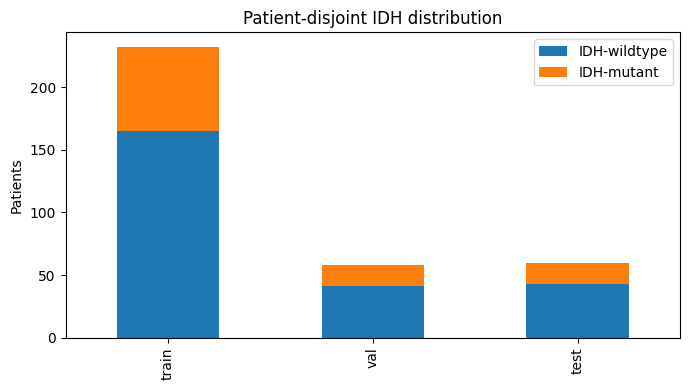

IMPORTANT: test subset locked but historical prior-study overlap is UNKNOWN.


In [ ]:
cfg = Config(data_dir=str(DATA), manifest_csv=str(MANIFEST), output_dir=str(OUTPUT),
    cache_dir='/content/idh_clean_restart_cache',seed=SEED,epochs=MAX_EPOCHS,
    batch_size=2,accumulation_steps=2,workers=2,early_patience=7,
    volume_shape=(112,112,112),input_resolution=112,voxel_spacing=1.5,
    locations=3,adjacent_slices=3,device='cuda',mixed_precision=True,
    augment_strength=0.32,use_class_weight=True,resume=True)
full=load_manifest(MANIFEST,DATA,True,cfg.sequences)
parts=locked_split(full,SPLIT_DIR,seed=SEED,test_n=TEST_PATIENTS,val_fraction=0.20)
summary=pd.DataFrame([{'split':name,'patients':len(part),
      'IDH-wildtype':int((part.idh_label==0).sum()),
      'IDH-mutant':int((part.idh_label==1).sum())} for name,part in parts.items()])
display(summary)
summary.to_csv(OUTPUT/'patient_split_summary.csv',index=False)
assert sum(len(p) for p in parts.values())==len(full)
fig,ax=plt.subplots(figsize=(7,4)); summary.set_index('split')[['IDH-wildtype','IDH-mutant']].plot.bar(stacked=True,ax=ax)
ax.set(title='Patient-disjoint IDH distribution',ylabel='Patients',xlabel='')
plt.tight_layout();plt.savefig(OUTPUT/'dataset_split_distribution.png',dpi=180);plt.show()
print('IMPORTANT: test subset locked but historical prior-study overlap is UNKNOWN.')


## 6. Actual MRI examples (professor display)
Displays all four registered MRI sequences from two training patients; masks guide the tumour-centred crop where provided.

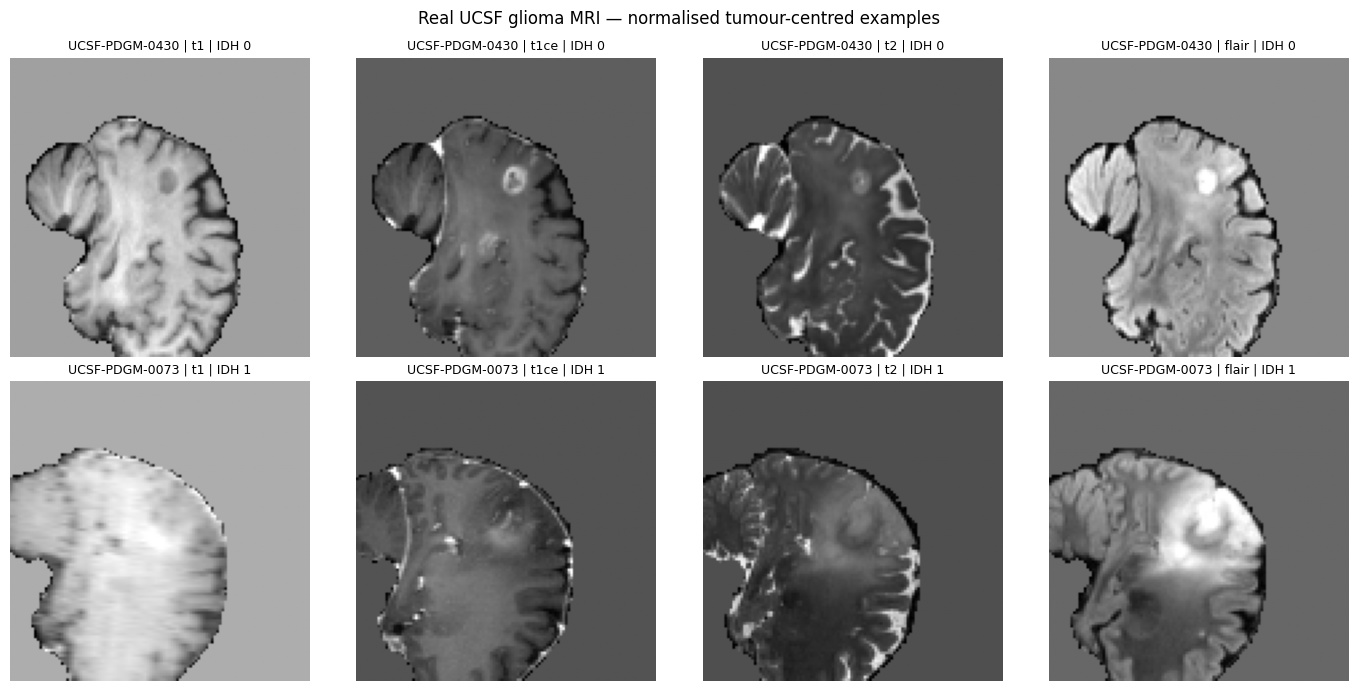

In [ ]:
fig,axs=plt.subplots(2,4,figsize=(14,7))
shown=parts['train'].groupby('idh_label').head(1)
for j,(_,patient) in enumerate(shown.iterrows()):
    vol,seg=cached_preprocess(patient,cfg)
    slices=volume_to_25d(vol,cfg,seg)
    for m in range(4):
        view=slices[1,m*cfg.adjacent_slices+cfg.adjacent_slices//2].numpy()
        axs[j,m].imshow(view,cmap='gray'); axs[j,m].axis('off')
        axs[j,m].set_title(f'{patient.patient_id} | {cfg.sequences[m]} | IDH {patient.idh_label}',fontsize=9)
plt.suptitle('Real UCSF glioma MRI — normalised tumour-centred examples')
plt.tight_layout();plt.savefig(OUTPUT/'real_mri_examples.png',dpi=180);plt.show()


## 7. Transfer learning + optimisation + fine-tuning
**Where is fine-tuning?** In the preceding `idh_experiments.py` file, `run_training()` freezes the ImageNet-pretrained ResNet/EfficientNet backbone for `freeze_pretrained_epochs=2` and unfreezes it from epoch 3 onwards. Training uses **AdamW, cosine LR scheduling, weight decay, class-weighted BCE loss, mixed precision, augmentation, early stopping and validation-based best checkpoint selection**.

The default experiments compare two ResNet-18 MRI crops/learning rates and an EfficientNet-B0 pretrained backbone. Optionally set `RUN_SCRATCH=True` above and rerun Section 3 before Section 7 to include an untrained-weight CNN reference. **Full MRI training is performed only when this cell executes.**


In [11]:
from idh_core import seed_everything
TRIALS=[]
if RUN_SCRATCH:
    TRIALS.append(('cnn_from_scratch_112_lr3e4','baseline',dict(
        backbone='light_cnn',pretrained_backbone=False,lr=3e-4,weight_decay=1e-4,
        freeze_pretrained_epochs=0,input_resolution=112,volume_shape=(112,112,112))))
if RUN_RESNET_112:
    TRIALS.append(('resnet18_112_lr1e4_aug','a2',dict(
        backbone='resnet18',pretrained_backbone=True,lr=1e-4,weight_decay=1e-4,
        freeze_pretrained_epochs=2,input_resolution=112,volume_shape=(112,112,112))))
if RUN_RESNET_96:
    TRIALS.append(('resnet18_96_lr3e5_aug','a2',dict(
        backbone='resnet18',pretrained_backbone=True,lr=3e-5,weight_decay=5e-5,
        freeze_pretrained_epochs=2,input_resolution=96,volume_shape=(96,96,96))))
if RUN_EFFICIENTNET:
    TRIALS.append(('efficientnet_b0_112_lr1e4_aug','a2',dict(
        backbone='efficientnet_b0',pretrained_backbone=True,lr=1e-4,weight_decay=1e-4,
        freeze_pretrained_epochs=2,input_resolution=112,volume_shape=(112,112,112))))
assert TRIALS,'Enable at least one training experiment in Section 3'
for i,(name,variant,change) in enumerate(TRIALS,1):
    dest=OUTPUT/'experiments'/name
    if (dest/'best.pt').is_file() and (dest/'val_predictions.csv').is_file():
        print('REUSING COMPLETED EXPERIMENT:',name); continue
    print(f'[{i}/{len(TRIALS)}] STARTING:',name)
    trial=replace(cfg,**change,seed=SEED+i)
    model,_=run_training(parts,trial,experiment=variant,experiment_dir=dest,evaluate_test=False)
    del model; gc.collect(); torch.cuda.empty_cache()
    if (dest/'val_predictions.csv').exists():
        (dest/'last.pt').unlink(missing_ok=True) # keep best.pt; save Drive space
print('All selected training runs complete. Final test still locked.')


[1/3] STARTING: resnet18_112_lr1e4_aug
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 176MB/s]


a2: 11,279,490 trainable parameters
Pretrained backbone warm-up: frozen for 2 epochs
a2 01: train_loss=0.9974 val_loss=0.8969 val_AUROC=0.8170731707317074 best_epoch=1
a2 02: train_loss=0.9767 val_loss=0.8631 val_AUROC=0.842180774748924 best_epoch=2
Unfreezing pretrained ResNet backbone for fine-tuning
a2 03: train_loss=0.8173 val_loss=0.6469 val_AUROC=0.8974175035868006 best_epoch=3
a2 04: train_loss=0.7484 val_loss=0.6484 val_AUROC=0.9347202295552367 best_epoch=4
a2 05: train_loss=0.5618 val_loss=0.7063 val_AUROC=0.8938307030129125 best_epoch=4
a2 06: train_loss=0.4272 val_loss=0.7570 val_AUROC=0.9067431850789096 best_epoch=4
a2 07: train_loss=0.2894 val_loss=0.7533 val_AUROC=0.9196556671449068 best_epoch=4
a2 08: train_loss=0.1575 val_loss=0.9317 val_AUROC=0.9024390243902439 best_epoch=4
a2 09: train_loss=0.1164 val_loss=0.8365 val_AUROC=0.8988522238163558 best_epoch=4
a2 10: train_loss=0.0587 val_loss=0.9002 val_AUROC=0.8866571018651362 best_epoch=4
a2 11: train_loss=0.0476 val_los

100%|██████████| 20.5M/20.5M [00:00<00:00, 155MB/s]


a2: 4,183,198 trainable parameters
Pretrained backbone warm-up: frozen for 2 epochs
a2 01: train_loss=1.0184 val_loss=0.9486 val_AUROC=0.7905308464849354 best_epoch=1
a2 02: train_loss=0.9269 val_loss=0.8936 val_AUROC=0.8550932568149211 best_epoch=2
Unfreezing pretrained ResNet backbone for fine-tuning
a2 03: train_loss=0.9525 val_loss=0.7638 val_AUROC=0.8995695839311335 best_epoch=3
a2 04: train_loss=0.8678 val_loss=0.6202 val_AUROC=0.9053084648493543 best_epoch=4
a2 05: train_loss=0.9843 val_loss=0.5163 val_AUROC=0.9296987087517934 best_epoch=5
a2 06: train_loss=0.8739 val_loss=0.6830 val_AUROC=0.8981348637015782 best_epoch=5
a2 07: train_loss=0.8766 val_loss=0.6130 val_AUROC=0.9175035868005739 best_epoch=5
a2 08: train_loss=0.8402 val_loss=0.7840 val_AUROC=0.9225251076040173 best_epoch=5
a2 09: train_loss=0.5723 val_loss=0.6243 val_AUROC=0.9368723098995695 best_epoch=9
a2 10: train_loss=0.6987 val_loss=0.7995 val_AUROC=0.9426111908177905 best_epoch=10
a2 11: train_loss=0.7469 val_lo

## 8. Validation-only hyperparameter, threshold and ensemble comparison
This is the proper place to choose a model. **Do not use final-test scores to select an architecture or threshold.**

In [12]:
from itertools import combinations
from sklearn.metrics import balanced_accuracy_score, f1_score

def select_threshold(y,p):
    scores=[]
    for t in np.round(np.arange(.15,.851,.01),3):
        yp=(np.asarray(p)>=t).astype(int)
        scores.append((balanced_accuracy_score(y,yp),f1_score(y,yp,average='macro',zero_division=0),-abs(t-.5),float(t)))
    return max(scores)[-1]

val_frames={}; rows=[]
for name,variant,changes in TRIALS:
    file=OUTPUT/'experiments'/name/'val_predictions.csv'
    if not file.exists():continue
    frame=pd.read_csv(file).sort_values('patient_id').reset_index(drop=True)
    if set(frame.patient_id)!=set(parts['val'].patient_id):
        raise ValueError(f'{name}: validation IDs do not match locked split')
    val_frames[name]=frame
    t=select_threshold(frame.idh_label,frame.probability)
    m=metrics_binary(frame.idh_label,frame.probability,t)
    rows.append({'candidate':name,'category':'single','crop':changes['input_resolution'],
       'learning_rate':changes['lr'],'threshold':t,'val_auroc':m['auroc'],
       'val_bal_acc':m['balanced_accuracy'],'val_macro_f1':m['macro_f1'],'val_brier':m['brier']})
for a,b in combinations(list(val_frames),2):
    v=val_frames[a][['patient_id','idh_label','probability']].rename(columns={'probability':'p1'})
    v=v.merge(val_frames[b][['patient_id','probability']].rename(columns={'probability':'p2'}),on='patient_id',validate='one_to_one')
    p=v[['p1','p2']].mean(axis=1).to_numpy()
    t=select_threshold(v.idh_label,p); m=metrics_binary(v.idh_label,p,t)
    rows.append({'candidate':a+' + '+b,'category':'ensemble','crop':None,'learning_rate':None,
       'threshold':t,'val_auroc':m['auroc'],'val_bal_acc':m['balanced_accuracy'],
       'val_macro_f1':m['macro_f1'],'val_brier':m['brier']})
if not rows:raise ValueError('Train experiments in Section 7 before model selection')
ranking=pd.DataFrame(rows).sort_values(['val_auroc','val_bal_acc','val_macro_f1','val_brier'],
    ascending=[False,False,False,True]).reset_index(drop=True)
display(ranking.round(4))
ranking.to_csv(OUTPUT/'VALIDATION_ranked_models.csv',index=False)
chosen=ranking.iloc[0].to_dict()
chosen_file=OUTPUT/'VALIDATION_chosen.json'
flag=OUTPUT/'FINAL_TEST_ALREADY_OPENED.flag'
if flag.exists():
    old=json.loads(flag.read_text())
    if chosen['candidate']!=old['candidate'] or abs(float(chosen['threshold'])-old['threshold'])>1e-8:
        raise ValueError('Final test already opened with a DIFFERENT model/threshold; cannot silently reselect.')
chosen_file.write_text(json.dumps(chosen,indent=2,default=str))
print('VALIDATION WINNER:',chosen['candidate'],'| classification threshold:',round(float(chosen['threshold']),3))


,candidate,category,crop,learning_rate,threshold,val_auroc,val_bal_acc,val_macro_f1,val_brier
0,efficientnet_b0_112_lr1e4_aug,single,112.0,0.0001,0.81,0.9412,0.8508,0.8389,0.1449
1,resnet18_112_lr1e4_aug + efficientnet_b0_112_l...,ensemble,NaN,NaN,0.71,0.9412,0.8508,0.8389,0.1385
2,resnet18_112_lr1e4_aug,single,112.0,0.0001,0.70,0.9340,0.8608,0.8134,0.1904
3,resnet18_112_lr1e4_aug + resnet18_96_lr3e5_aug,ensemble,NaN,NaN,0.59,0.9340,0.8558,0.8262,0.1484
4,resnet18_96_lr3e5_aug + efficientnet_b0_112_lr...,ensemble,NaN,NaN,0.52,0.9225,0.8508,0.8389,0.1226
5,resnet18_96_lr3e5_aug,single,96.0,0.0000,0.42,0.9154,0.8436,0.8092,0.1348


VALIDATION WINNER: efficientnet_b0_112_lr1e4_aug | classification threshold: 0.81


## 9. Professor outputs — training curves and model comparisons
These plots are **validation-only**: they can be shown before opening the final test.

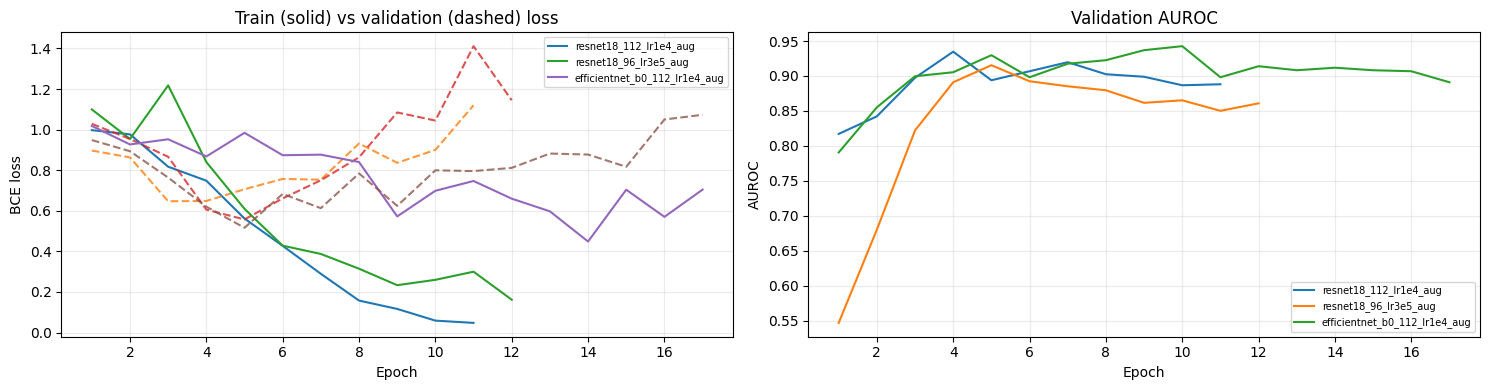

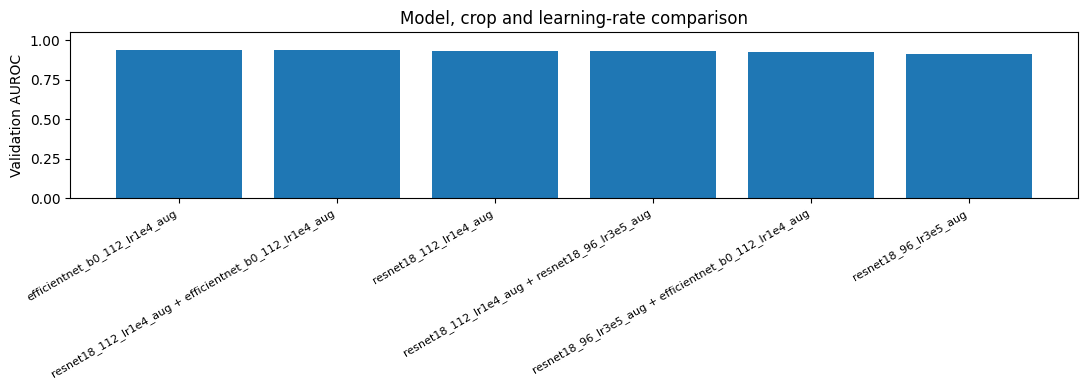

Select the final model from VALIDATION only, then change RUN_FINAL_TEST=True in Section 3.


In [13]:
fig,axes=plt.subplots(1,2,figsize=(15,4))
for name,_,_ in TRIALS:
    file=OUTPUT/'experiments'/name/'history.csv'
    if not file.exists():continue
    h=pd.read_csv(file)
    axes[0].plot(h.epoch,h.train_loss,label=name)
    axes[0].plot(h.epoch,h.val_loss,ls='--',alpha=.8)
    axes[1].plot(h.epoch,h.val_auroc,label=name)
axes[0].set(xlabel='Epoch',ylabel='BCE loss',title='Train (solid) vs validation (dashed) loss')
axes[1].set(xlabel='Epoch',ylabel='AUROC',title='Validation AUROC')
for ax in axes:ax.grid(alpha=.25);ax.legend(fontsize=7)
plt.tight_layout();plt.savefig(OUTPUT/'training_curves.png',dpi=180);plt.show()
fig,ax=plt.subplots(figsize=(max(11,len(ranking)*1.6),4))
ax.bar(np.arange(len(ranking)),ranking.val_auroc)
ax.set_xticks(np.arange(len(ranking)),ranking.candidate,rotation=30,ha='right',fontsize=8)
ax.set(ylabel='Validation AUROC',ylim=(0,1.05),title='Model, crop and learning-rate comparison')
plt.tight_layout();plt.savefig(OUTPUT/'validation_models.png',dpi=180);plt.show()
print('Select the final model from VALIDATION only, then change RUN_FINAL_TEST=True in Section 3.')


## 10. Final internal held-out test — open once
**To show final test accuracy:** finish Sections 7–9, set `RUN_FINAL_TEST=True` in Section 3, execute Section 3 again, then run this cell. It saves actual predictions, metrics, confusion matrix, ROC and PR plots in Google Drive.

**Caution:** split is test-unseen relative to THIS restart's training/validation, but historical overlap with the earlier lost experiments **cannot be verified**. It is not external validation.


Final test OPENED and LOCKED; do not change models or thresholds using this score.


,Metric,Result
0,n,60
1,n_wildtype,43
2,n_mutant,17
3,accuracy,0.85
4,balanced_accuracy,0.80643
5,precision,0.75
6,recall,0.705882
7,sensitivity,0.705882
8,specificity,0.906977
9,macro_f1,0.811912


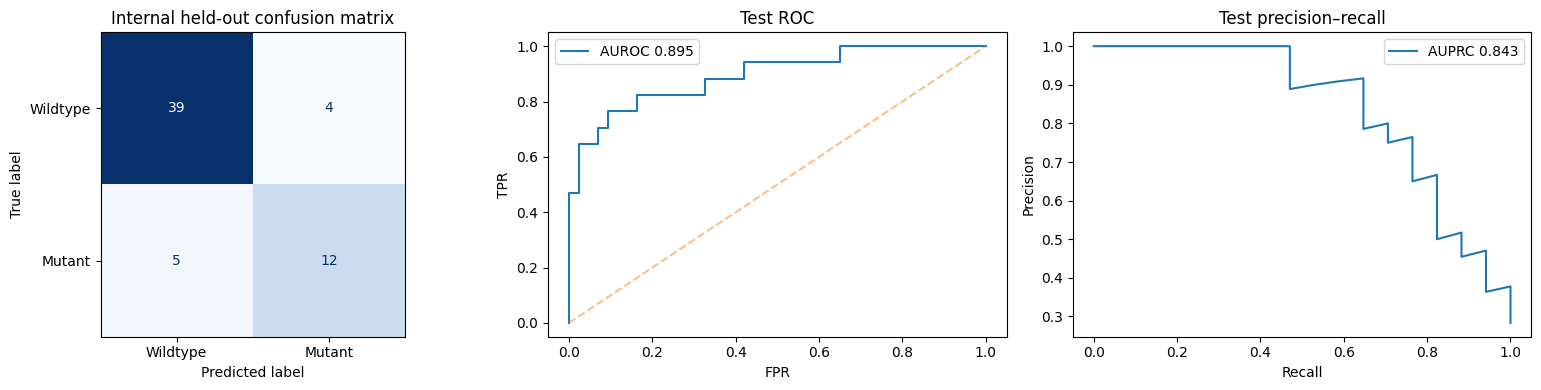


=== RESULT SUMMARY FOR PROFESSOR ===
Cohort: 350 subjects; internal test: 60
Accuracy: 85.0% | Balanced accuracy: 80.6% | AUROC: 0.895
Macro-F1: 0.812 | Sensitivity: 70.6% | Specificity: 90.7%
Majority-class baseline accuracy: 71.7%
Fine-tuning: ImageNet-pretrained ResNet/EfficientNet unfrozen after 2 warm-up epochs
Optimisation: AdamW, cosine LR, class weight, MRI augmentation, early stopping, validation tuning
Limitations: internal single-centre test, unknown overlap with previously viewed patients; masks required, no external scanner audit
Saved results: /content/drive/MyDrive/IDH_Audit/results/CLEAN_RESTART_2026_OCT


,patient_id,idh_label,probability,predicted_class
0,UCSF-PDGM-XXXX,0,0.012477,0
1,UCSF-PDGM-XXXX,0,0.012272,0
2,UCSF-PDGM-XXXX,0,0.011101,0
3,UCSF-PDGM-XXXX,0,0.010659,0
4,UCSF-PDGM-XXXX,0,0.015589,0
5,UCSF-PDGM-XXXX,0,0.009950,0
6,UCSF-PDGM-XXXX,0,0.020603,0
7,UCSF-PDGM-XXXX,0,0.117288,0
8,UCSF-PDGM-XXXX,0,0.011759,0
9,UCSF-PDGM-XXXX,0,0.012596,0


In [18]:
from torch.utils.data import DataLoader
from sklearn.metrics import roc_curve, precision_recall_curve, ConfusionMatrixDisplay

flag=OUTPUT/'FINAL_TEST_ALREADY_OPENED.flag'
if not RUN_FINAL_TEST:
    print('FINAL TEST IS LOCKED. Finish model selection, set RUN_FINAL_TEST=True in Section 3, then run Section 10.')
else:
    if flag.exists():
        saved=json.loads(flag.read_text())
        if saved['candidate']!=chosen['candidate'] or abs(saved['threshold']-float(chosen['threshold']))>1e-8:
            raise ValueError('Final test already opened with a different model/threshold. Cannot reselect.')
        final=pd.read_csv(OUTPUT/'FINAL_TEST_predictions.csv')
        final_metrics=json.loads((OUTPUT/'FINAL_TEST_metrics.json').read_text())
        print('Displaying previously LOCKED test predictions — not evaluating a different model.')
    else:
        predicted=[]
        for name in chosen['candidate'].split(' + '):
            ck=OUTPUT/'experiments'/name/'best.pt'
            if not ck.exists():raise FileNotFoundError('Missing checkpoint: '+str(ck))
            model,loaded,_=load_checkpoint(ck,device='cuda')
            loaded.cache_dir=cfg.cache_dir
            dl=DataLoader(PatientDataset(parts['test'],loaded),batch_size=2,
                          shuffle=False,num_workers=2,pin_memory=True)
            tmp=predict_loader(model,dl,loaded).sort_values('patient_id').reset_index(drop=True)
            predicted.append(tmp)
            del model,dl;gc.collect();torch.cuda.empty_cache()
        if not all(p.patient_id.equals(predicted[0].patient_id) for p in predicted):
            raise ValueError('Ensemble test patient order mismatch')
        final=predicted[0][['patient_id','idh_label']].copy()
        final['probability']=np.mean([p.probability.to_numpy(dtype=float) for p in predicted],axis=0)
        threshold=float(chosen['threshold'])
        final['predicted_class']=(final.probability>=threshold).astype(int)
        final_metrics=metrics_binary(final.idh_label,final.probability,threshold)
        # Bootstrap CIs with the fixed validation-selected threshold, not the default .5
        gen=np.random.default_rng(SEED+10)
        acc_values=[];auc_values=[]
        yy=final.idh_label.to_numpy(int);pp=final.probability.to_numpy(float)
        for _ in range(1000):
            idx=gen.integers(0,len(yy),len(yy))
            mm=metrics_binary(yy[idx],pp[idx],threshold)
            acc_values.append(mm['accuracy'])
            if mm['auroc'] is not None:auc_values.append(mm['auroc'])
        final_metrics['accuracy_ci95']=[float(v) for v in np.percentile(acc_values,[2.5,97.5])]
        final_metrics['auroc_ci95']=[float(v) for v in np.percentile(auc_values,[2.5,97.5])] if auc_values else [None,None]
        final_metrics.update({'candidate':chosen['candidate'],'threshold_from_validation':threshold,
          'evaluation_type':'internal_patient_disjoint','previous_study_patient_overlap':'unknown',
          'independent_external_validation':'not_performed'})
        final.to_csv(OUTPUT/'FINAL_TEST_predictions.csv',index=False)
        (OUTPUT/'FINAL_TEST_metrics.json').write_text(json.dumps(final_metrics,indent=2,allow_nan=False))
        flag.write_text(json.dumps({'candidate':chosen['candidate'],'threshold':threshold,
          'test_n':len(final)},indent=2))
        print('Final test OPENED and LOCKED; do not change models or thresholds using this score.')
    display(pd.DataFrame([(k,v) for k,v in final_metrics.items() if isinstance(v,(int,float,str))],
                         columns=['Metric','Result']))
    fig,axes=plt.subplots(1,3,figsize=(16,4))
    ConfusionMatrixDisplay(np.asarray(final_metrics['confusion_matrix']),
      display_labels=['Wildtype','Mutant']).plot(ax=axes[0],cmap='Blues',colorbar=False)
    axes[0].set_title('Internal held-out confusion matrix')
    fpr,tpr,_=roc_curve(final.idh_label,final.probability)
    axes[1].plot(fpr,tpr,label=f'AUROC {final_metrics["auroc"]:.3f}')
    axes[1].plot([0,1],[0,1],'--',alpha=.5)
    axes[1].set(xlabel='FPR',ylabel='TPR',title='Test ROC');axes[1].legend()
    p,r,_=precision_recall_curve(final.idh_label,final.probability)
    axes[2].plot(r,p,label=f'AUPRC {final_metrics["auprc"]:.3f}')
    axes[2].set(xlabel='Recall',ylabel='Precision',title='Test precision–recall');axes[2].legend()
    fig.tight_layout();fig.savefig(OUTPUT/'FINAL_TEST_confusion_roc_pr.png',dpi=190);plt.show()
    majority=int(parts['train'].idh_label.value_counts().idxmax())
    majority_acc=float((final.idh_label==majority).mean())
    print('\n=== RESULT SUMMARY FOR PROFESSOR ===')
    print('Cohort:',len(full),'subjects; internal test:',len(final))
    print(f'Accuracy: {final_metrics["accuracy"]:.1%} | Balanced accuracy: {final_metrics["balanced_accuracy"]:.1%} | AUROC: {final_metrics["auroc"]:.3f}')
    print(f'Macro-F1: {final_metrics["macro_f1"]:.3f} | Sensitivity: {final_metrics["sensitivity"]:.1%} | Specificity: {final_metrics["specificity"]:.1%}')
    print(f'Majority-class baseline accuracy: {majority_acc:.1%}')
    print('Fine-tuning: ImageNet-pretrained ResNet/EfficientNet unfrozen after 2 warm-up epochs')
    print('Optimisation: AdamW, cosine LR, class weight, MRI augmentation, early stopping, validation tuning')
    print('Limitations: internal single-centre test, unknown overlap with previously viewed patients; masks required, no external scanner audit')
    print('Saved results:',OUTPUT)
    display(final.head(15))


## 11. What to say to your professor

> We developed a 2.5D multi-sequence MRI model to predict the molecular IDH mutation status of glioma patients. Verified molecular labels came from the UCSF-PDGM cohort. We used T1, contrast T1, T2 and FLAIR, with tumour-mask-assisted preprocessing and patient-disjoint training/validation/test splits. We compared ImageNet-pretrained ResNet-18 and EfficientNet-B0, froze pretrained layers for two warm-up epochs and then fine-tuned them. We used AdamW, cosine scheduling, class-weighted loss, MRI augmentation, early stopping and validation-only hyperparameter and threshold selection. Accuracy, balanced accuracy, sensitivity, specificity, AUROC and F1 are displayed above after the final test is unlocked.

**Be accurate about results:** This **restarted** notebook contains no pre-filled accuracy. Only the output after genuine training shows its score. Because earlier test-patient IDs were lost, we cannot prove the new internal test has zero overlap with patients inspected previously. Single-institution data and tumour-mask dependence also prevent claims of clinical generalisation or removal of acquisition shortcuts. To complete the full research paper, we still need external multi-vendor cohorts, acquisition probes, perturbation robustness audits, and proper shortcut-mitigation ablations.
